# Communication score and its multi-scale Moran's I

Post-hoc on **one** already-trained InterScale model, pulled from its wandb sweep. Nothing is
retrained here.

The gene-loadings analysis (`4_a_decoder_stability.ipynb`) says which genes load on which
local/global decoder dimension. This notebook turns that into a **per-cell, gene-grounded
score** and asks whether its spatial autocorrelation separates the two scales:

1. `s_ie = sum_{f in topN(e)} Ghat_fe * xtilde_if` — the signed, L1-normalized standardized
   loading of dimension `e` applied to **measured** per-gene z-scored expression. **One score
   per cell per informative dimension**, each built only from that dimension's own top-N
   genes. These are the output: `obs["commscore_{scale}_dim{e}"]`, `obsm["commscore_{scale}"]`.
2. the per-scale aggregates `S_local` / `S_global` are also written, but only because the
   gene-set-level swap control is defined on them. They are **not** what this notebook reads:
   a scale's dimensions carry different programs, and collapsing them averages a dimension
   with a strong spatial signal into one without.
3. multi-scale Moran's I of each dimension's score over k = 4 … 128 neighbours, with the AUC
   over log2 k and the decay slopes either side of k = 16.
4. two controls (expression-matched random gene sets; local<->global gene-set swap) and a
   ligand–receptor enrichment per dimension.

**Why measured expression and not the reconstruction.** The decoders are linear, so one
dimension's reconstructed contribution is `W_fe * H_ie`, whose gene-sum is `H_ie * const` —
exactly collinear with the embedding. Scoring measured expression is what makes this an
independent quantity rather than a relabelled embedding. For the same reason the score uses
cell-intrinsic expression, never neighbourhood-averaged expression: smoothing first and then
measuring spatial autocorrelation would be circular.

The method is specified in `src/interscale_communication_score.md`; `src/interscale_communication_score.py`
is the reference implementation and is called rather than re-derived here.

In [1]:
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

warnings.filterwarnings("ignore")

In [2]:
# LRZ home
if os.path.exists("/dss/dsshome1/05/di93tig"):
    print("LRZ cluster")
    CLUSTER = "LRZ"
    BASE_DIR_REPO = "/dss/dsshome1/05/di93tig/1_projects"
    BASE_DIR_PROJECT = "/dss/dssfs03/tumdss/pn36po/pn36po-dss-0002/di93tig/Projects/A3_InterScale"
elif os.path.exists("/home/icb/francesca.drummer/"):
    print("HPC cluster")
    CLUSTER = "HPC"
    BASE_DIR_REPO = "/home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility/"
    BASE_DIR_PROJECT = "/lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/"
else:
    print("unkown")
    CLUSTER = "unknown"
DATA = "legnini23"

project_root = Path(BASE_DIR_REPO)  # for `from src.* import ...`
sys.path.insert(0, str(project_root))

INTERSCALE_REPO = project_root.parent / "interscale"
REGISTRY = INTERSCALE_REPO / "config_files" / "registry.yaml"
assert REGISTRY.exists(), f"registry not found: {REGISTRY}"

import yaml

with open(os.path.join(BASE_DIR_REPO, "figures/config.yml")) as f:
    config = yaml.safe_load(f)
slides = config["slide_examples"][DATA]

HPC cluster


## Which trained model

One seed of one arm. The checkpoint comes from the sweep's wandb artifact
(`model-<run_id>:best`), which is the surviving copy — the `model.save` trees these runs wrote
to no longer exist on lustre. See `4_a_decoder_stability.ipynb` for the two arms.

In [3]:
MASKING = "cell"  # "cell" | "gene"
SEED = 40

ARMS = {
    "cell": {"task": "node_reg", "sweep_id": "ze40fzaz", "overrides": {}},
    "gene": {
        "task": "node_reg_genemask",
        "sweep_id": "dty3dlk3",
        # The sweep pinned the rate below the task file's 0.5; it has to be reapplied or the
        # config recorded here is not the one that trained.
        "overrides": {"dataset.mask_percentage": 0.25},
    },
}
ARM = ARMS[MASKING]
TASK, SWEEP_ID = ARM["task"], ARM["sweep_id"]

ARTIFACT_DIR = Path(BASE_DIR_PROJECT) / "wandb_artifacts"
RESULTS_DIR = Path(BASE_DIR_PROJECT) / "results" / DATA / f"comm_score_{MASKING}_seed{SEED}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"model     {DATA}/{TASK}, sweep {SWEEP_ID}, seed {SEED}")
print(f"artifacts {ARTIFACT_DIR}\nresults   {RESULTS_DIR}")

model     legnini23/node_reg, sweep ze40fzaz, seed 40
artifacts /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/wandb_artifacts
results   /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/legnini23/comm_score_cell_seed40


## Analysis settings

`TOP_N` is deliberately smaller than the N = 10 the method sheet suggests. This panel has **88
genes**: at N = 10 over ~5 informative dimensions a scale's gene set is half the panel, and the
expression-matched null draws the same number of genes — so the "random" control would be
almost the panel itself and the comparison would be vacuous. The sensitivity cell below re-runs
the headline numbers at N = 3, 5 and 10 so the conclusion is not an artefact of this choice.

In [4]:
TOP_N = 5
KS = (4, 8, 16, 32, 64, 128)
K_SPLIT = 16
# How topN(e) is chosen, and which genes are eligible at all. The method sheet's rule is
# "largest |G_fe|", which is right when sd(X_f) is comparable across genes. It is NOT right
# here, and the diagnostic cell further down shows why: G_fe = W_fe * sd(H_e) / sd(X_f), so on
# a targeted panel the 1/sd(X_f) factor puts the barely-detected genes at the top of EVERY
# dimension. "loading_x_sd" cancels that factor and is what
# interscale.evaluation.get_genes_dim ranks by, i.e. the rule the gene-loadings figures use.
RANK_BY = "loading_x_sd"  # "abs_loading" = the method sheet's literal rule
MIN_DETECT_FRAC = 0.01  # a gene in <1% of cells carries no z-score signal, only 1/sd noise
# Fraction of cumulative dimension importance kept per scale. 0.60 is the cutoff the published
# CosMx gene-loadings figure uses; on a 16-dimensional latent it leaves a handful of dimensions
# per scale, which is what keeps the gene sets small relative to an 88-gene panel.
CUMULATIVE_CUTOFF = 0.60
N_CONTROL_DRAWS = 30
SAMPLE_KEY = "sample"

## Load data

Same preprocessing as `4_a_decoder_stability.ipynb`: SHH rings, then the zero-expression filter
the models were trained under. Inference has to filter identically or the per-sample graphs
handed to the model are not the graphs it was trained on.

In [5]:
adata = sc.read_h5ad(f"{BASE_DIR_PROJECT}/data/{DATA}.h5ad")

from interscale.tl import clustering, remove_zero_expression_cells

adata.obs.drop(columns=["SHH_zone"], errors="ignore", inplace=True)
# Last edge open-ended on purpose: a closed edge at 6000 drops the 685 cells of slide1_C2-2 that
# reach further, and the resulting NaN propagates into the sample field scvi registers.
clustering.create_spatial_cluster_distance(
    adata, "SHH", "sample",
    distance_bins=[0, 200, 2000, 3000, np.inf],
    bin_labels=["SHH", "near", "medium", "far"],
    threshold=95,
)
assert adata.obs["SHH_zone"].isna().sum() == 0

adata.X = adata.layers["raw"]
adata = remove_zero_expression_cells(adata)
adata

Nr. of zero expression cells: 648


AnnData object with n_obs × n_vars = 43114 × 88
    obs: 'Cell', 'Area', 'x', 'y', 'sample', 'condition', 'organoid', 'obs_names', 'split', 'dist_to_SHH', 'SHH_zone'
    var: 'gene_ids', 'feature_types'
    obsm: 'spatial'
    layers: 'log1p_norm', 'norm_ftsqrt', 'raw', None (.X)

## Load the model from wandb and run inference

In [6]:
from functools import partial

import interscale
from interscale.evaluation import calculate_dim_importance, gene_loadings

import src.interscale_communication_score as M
from src.decoder_stability import GROUP_COLORS, build_cfg as _build_cfg, run_seed_inference
from src.wandb import sweep_checkpoint_loader

import wandb

wandb.login()

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /home/icb/francesca.drummer/.netrc.


wandb: Currently logged in as: francesca-drummer to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


True

In [7]:
build_cfg = partial(
    _build_cfg,
    DATA,
    TASK,
    REGISTRY,
    # cfg.model.save is where the training job wrote; nothing here reads it, because the
    # checkpoint comes from the run's artifact.
    models_dir=ARTIFACT_DIR,
    overrides={"optim.n_epochs": 300, **ARM["overrides"]},
)

cfg = build_cfg(SEED)
LAYER_KEY = cfg.dataset.layer_key
N_EMBED = cfg.model.n_embed
assert cfg.model.decoder.dual_decoder, "no local decoder, so there is no local/global contrast"

# Below max_seq_len, tl/padding.py random-subsamples each graph instead of erroring, so the
# embeddings would come from a graph the model never saw.
sizes = adata.obs[cfg.dataset.sample_key[0]].value_counts()
sizes = sizes[sizes > 0]
assert sizes.max() <= cfg.model.global_component.parameters.max_seq_len
print(f"layer_key {LAYER_KEY} | n_embed {N_EMBED} | {len(sizes)} slides, largest {sizes.max()} cells")

layer_key log1p_norm | n_embed 16 | 17 slides, largest 4299 cells


In [8]:
_y = adata.layers[LAYER_KEY]
from scipy.sparse import issparse

y_true = np.asarray(_y.todense() if issparse(_y) else _y, dtype=np.float64)

load_from_sweep = sweep_checkpoint_loader(SWEEP_ID, ARTIFACT_DIR)

# One seed, but through the same inference path the stability notebook uses, so the embeddings
# land under the f"{seed}_" prefix that gene_loadings and calculate_dim_importance expect. The
# per-gene csv it writes is the evidence that the checkpoint that loaded reconstructs sensibly.
adata, models, local_emb, global_emb, performance = run_seed_inference(
    adata,
    [SEED],
    build_cfg,
    None,  # checkpoints come from wandb
    RESULTS_DIR,
    load_model=load_from_sweep,
    y_true=y_true,
    repro_seed=40,
)
model = models[SEED]

sweep ze40fzaz: seed 40 -> t3cxaxb3, seed 41 -> phmtuc86, seed 42 -> 9p9ixuw9, seed 43 -> lshqnbqa, seed 44 -> rjo32qaa


wandb:   1 of 1 files downloaded.  


Loading model from /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/wandb_artifacts/t3cxaxb3/model.pt
Unclear checkpoint format. Attempting remapping anyway.
State dict remapping applied. Source detected: unknown
Load GEX from .layers/log1p_norm
INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


... (10 outputs left out)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  



seed 40: wrote model_40_performance.csv (704 rows)
  per-gene medians on the test split:
               r2       mse   pearson  cosine_sim
decoder                                          
global  -2.615279  0.414003  0.132976    0.236551
local   -3.530209  0.509460  0.219187    0.043355

embeddings: local (43114, 16), global (43114, 16) per seed


## Standardized loadings and informative dimensions

`gene_loadings` writes `G_fe = W_fe * sd(H_e) / sd(X_f)` into `adata.varm`, rows aligned to
`adata.var_names` — which is exactly the `G` the score consumes, so no re-derivation.

The LOCAL loadings are standardized by the LOCAL embedding's std. The local decoder decodes the
local embedding, so standardizing those by the global embedding rescales every local dimension
by the wrong constant, which changes the dimension ranking and therefore the gene sets.

In [9]:
gene_loadings(
    adata,
    model,
    local_latent_key=f"{SEED}_local_emb",
    global_latent_key=f"{SEED}_global_emb",
    local_varm_key=f"{SEED}_local_std_gene_loadings",
    global_varm_key=f"{SEED}_global_std_gene_loadings",
    layer_key=LAYER_KEY,
)

G = {w: np.asarray(adata.varm[f"{SEED}_{w}_std_gene_loadings"]) for w in ("local", "global")}
DIMS = {}
for which in ("local", "global"):
    imp = calculate_dim_importance(
        adata, which=which, prefix=SEED, mode="full", use_ratio=True,
        cumulative_cutoff=CUMULATIVE_CUTOFF, spacing=2,
    )
    assert imp["dims_left"] is not None, f"no dimension selection for {which}"
    DIMS[which] = [int(e) for e in imp["dims_left"]]
    print(f"{which:6s}: G {G[which].shape}, {len(DIMS[which])} informative dims {DIMS[which]}")

local : G (88, 16), 4 informative dims [9, 7, 4, 13]
global: G (88, 16), 5 informative dims [13, 12, 7, 11, 9]


### Which genes the two ranking rules select — and why it matters here

`G_fe = W_fe · sd(H_e) / sd(X_f)`. On a targeted panel the `1/sd(X_f)` factor dominates, so
ranking by `|G_fe|` returns the **least-expressed** genes in every dimension — including genes
with zero counts, whose z-score is 0 in every cell and which therefore contribute nothing but
a wasted slot. Ranking by `|G_fe · sd(X_f)| = |W_fe · sd(H_e)|` (the gene's absolute swing per
SD of the dimension) cancels it, and is what `get_genes_dim` ranks by.

The table below is the evidence for that choice, not decoration: read `detect_frac`.

In [10]:
X_all = adata.layers[LAYER_KEY]
X_all = np.asarray(X_all.todense()) if hasattr(X_all, "todense") else np.asarray(X_all)
detect_frac = (X_all > 0).mean(0)
sd_X = X_all.std(0)
DETECTED = M.detection_mask(X_all, MIN_DETECT_FRAC)
print(f"{DETECTED.sum()}/{adata.n_vars} genes detected in >= {MIN_DETECT_FRAC:.0%} of cells; "
      f"{int((detect_frac == 0).sum())} have zero counts anywhere")

# One ranking matrix per scale, computed on the whole dataset so the gene set is fixed across
# slides: |G_fe * sd(X_f)| = |W_fe * sd(H_e)|.
RANK = {w: G[w] * sd_X[:, None] for w in ("local", "global")}

rule_sets = {}
for rule in ("abs_loading", "loading_x_sd"):
    for which in ("local", "global"):
        mask = None if rule == "abs_loading" else DETECTED
        rank = None if rule == "abs_loading" else RANK[which]
        idx = np.unique(np.concatenate([
            M._top_n_idx(G[which][:, e], TOP_N,
                         rank_col=None if rank is None else rank[:, e], gene_mask=mask)
            for e in DIMS[which]
        ]))
        rule_sets[(rule, which)] = idx
        print(f"{rule:13s} {which:6s}: {len(idx):2d} genes "
              f"({len(idx) / adata.n_vars:.0%} of panel), "
              f"detect_frac min {detect_frac[idx].min():.4f} median {np.median(detect_frac[idx]):.3f}")
        print(f"{'':22s}{sorted(adata.var_names[idx])}")

81/88 genes detected in >= 1% of cells; 0 have zero counts anywhere
abs_loading   local :  8 genes (9% of panel), detect_frac min 0.0005 median 0.002
                      ['AQP4', 'BCL11B', 'CDR1', 'FOXG1', 'NKX2.1', 'SIX6', 'TBR1', 'TREM2']
abs_loading   global:  8 genes (9% of panel), detect_frac min 0.0005 median 0.003
                      ['AQP4', 'ARG1', 'CDR1', 'FOXG1', 'HOPX', 'NKX2.1', 'TBR1', 'TREM2']
loading_x_sd  local : 15 genes (17% of panel), detect_frac min 0.1643 median 0.811
                      ['Circ.RMST', 'GLI2', 'GLI3', 'HHIP', 'IRX3', 'JUN', 'KLF13', 'MAP2', 'NKX2.2', 'NKX6.1', 'NKX6.2', 'PAX6', 'PTCH1', 'SOX2', 'STMN2']
loading_x_sd  global: 19 genes (22% of panel), detect_frac min 0.2394 median 0.823
                      ['CUL3', 'Circ.CDR1', 'Circ.RMST', 'DBX2', 'FOS', 'GLI1', 'GLI3', 'IRX3', 'JUN', 'JUNB', 'MAP2', 'NEUROG2', 'NKX6.1', 'PAX6', 'PTCH1', 'PTPRZ1', 'TUBB3', 'ZNF609', 'ZSWIM8']


In [11]:
# Per-gene Moran's I on the largest slide, for the genes each rule selects. A score can only be
# spatially autocorrelated if the genes it is built from are -- this is the cell that says
# whether a null result is about the programs or about the gene selection.
_big = adata.obs[SAMPLE_KEY].value_counts().index[0]
_sub = adata[adata.obs[SAMPLE_KEY] == _big]
_X = _sub.layers[LAYER_KEY]
_X = np.asarray(_X.todense()) if hasattr(_X, "todense") else np.asarray(_X)
_Xz, _coords = M.zscore_expression(_X), np.asarray(_sub.obsm["spatial"])
for rule in ("abs_loading", "loading_x_sd"):
    idx = np.unique(np.concatenate([rule_sets[(rule, w)] for w in ("local", "global")]))
    I = np.array([M.morans_I(_coords, _Xz[:, j], 16) for j in idx])
    print(f"{rule:13s} on {_big}: per-gene Moran's I (k=16) "
          f"median {np.nanmedian(I):.3f}, max {np.nanmax(I):.3f}, "
          f"{int(np.isnan(I).sum())} undefined (zero-variance gene)")
    print("   " + ", ".join(f"{g}:{v:.2f}" for g, v in zip(adata.var_names[idx], I)))

abs_loading   on slide1_D2-2: per-gene Moran's I (k=16) median 0.002, max 0.026, 4 undefined (zero-variance gene)
   AQP4:-0.00, ARG1:0.03, BCL11B:-0.00, CDR1:0.01, HOPX:0.01, NKX2.1:nan, SIX6:-0.00, TBR1:nan, FOXG1:nan, TREM2:nan


loading_x_sd  on slide1_D2-2: per-gene Moran's I (k=16) median 0.410, max 0.719, 0 undefined (zero-variance gene)
   Circ.CDR1:0.33, Circ.RMST:0.39, CUL3:0.13, DBX2:0.53, FOS:0.48, GLI1:0.34, GLI2:0.37, GLI3:0.45, HHIP:0.29, IRX3:0.50, JUN:0.41, JUNB:0.40, KLF13:0.11, MAP2:0.52, NEUROG2:0.30, NKX2.2:0.43, NKX6.1:0.72, NKX6.2:0.30, PAX6:0.45, PTCH1:0.51, PTPRZ1:0.48, SOX2:0.37, STMN2:0.46, TUBB3:0.54, ZNF609:0.37, ZSWIM8:0.08


In [12]:
gene_sets = {w: adata.var_names[rule_sets[(RANK_BY, w)]].tolist() for w in ("local", "global")}
print(f"\nusing rank_by={RANK_BY!r}")
print(f"shared by both scales: {sorted(set(gene_sets['local']) & set(gene_sets['global']))}")
print(f"local only : {sorted(set(gene_sets['local']) - set(gene_sets['global']))}")
print(f"global only: {sorted(set(gene_sets['global']) - set(gene_sets['local']))}")


using rank_by='loading_x_sd'
shared by both scales: ['Circ.RMST', 'GLI3', 'IRX3', 'JUN', 'MAP2', 'NKX6.1', 'PAX6', 'PTCH1']
local only : ['GLI2', 'HHIP', 'KLF13', 'NKX2.2', 'NKX6.2', 'SOX2', 'STMN2']
global only: ['CUL3', 'Circ.CDR1', 'DBX2', 'FOS', 'GLI1', 'JUNB', 'NEUROG2', 'PTPRZ1', 'TUBB3', 'ZNF609', 'ZSWIM8']


## Per-slide communication score and Moran's I

**The kNN graph is built within a slide, never across slides** — the slides are separate
coordinate systems, so a graph over the concatenated coordinates would join cells that are not
neighbours. Each slide is therefore scored on its own (which also z-scores expression within
slide, removing slide-level offsets), and the curves are averaged across slides afterwards.

Here the slide *is* the global component's receptive field: `dataset.sample_key` is `sample`,
so the transformer attends over the whole slide while the GCN sees a 200 µm radius.

In [13]:
# One column per informative dimension per scale -- these are the scores. The two collapsed
# aggregates are kept only because the gene-set-level controls are defined on them.
DIM_COLS = [f"commscore_{s}_dim{e}" for s in ("local", "global") for e in DIMS[s]]
AGG_COLS = [f"commscore_{s}_{a}" for s in ("local", "global") for a in ("l2", "signed")]
SCORE_COLS = DIM_COLS + AGG_COLS
slide_sizes = adata.obs[SAMPLE_KEY].value_counts()
SLIDES = sorted(slide_sizes[slide_sizes > max(KS) + 1].index)
print(f"{len(SLIDES)} slides, {slide_sizes.min()}-{slide_sizes.max()} cells each")

per_slide = {}
scores = {c: pd.Series(np.nan, index=adata.obs_names, dtype=float) for c in SCORE_COLS}

for slide in SLIDES:
    sub = adata[adata.obs[SAMPLE_KEY] == slide].copy()
    res = M.run_from_adata(
        sub,
        G_local=G["local"], G_global=G["global"],
        dims_local=DIMS["local"], dims_global=DIMS["global"],
        expr_layer=LAYER_KEY,
        embed_local_key=f"{SEED}_local_emb",
        embed_global_key=f"{SEED}_global_emb",
        spatial_key="spatial",
        top_n=TOP_N, ks=KS, n_control_draws=N_CONTROL_DRAWS, seed=0,
        # Ranking matrices computed once on the WHOLE dataset, so all 17 slides score the same
        # fixed gene set. Left to rank_by, each slide's own sd(X_f) would pick its own genes.
        rank_by=RANK_BY, rank_local=RANK["local"], rank_global=RANK["global"],
        gene_mask=DETECTED,
        # The null draws TOP_N genes, the size of ONE dimension's gene set, because a single
        # dimension's score is what it is being compared against. (Matched to the union instead,
        # it would average more genes than any one score does and sit too high.)
        control_n_genes=TOP_N,
    )
    per_slide[slide] = res
    for c in SCORE_COLS:
        scores[c].loc[sub.obs_names] = sub.obs[c].to_numpy()
    best = res["per_dim_table"].loc[res["per_dim_table"]["auc"].idxmax()]
    print(f"{slide:14s} n={sub.n_obs:5d}  best dim {best['scale']}{int(best['dim']):>3d} "
          f"AUC {best['auc']:.3f}  null {res['control_auc']['mean']:.3f}")

for c in SCORE_COLS:
    adata.obs[c] = scores[c]

17 slides, 1622-4299 cells each


slide1_A2-1    n= 3023  best dim global  9 AUC 0.146  null 0.024


slide1_A2-2    n= 1691  best dim global  9 AUC 0.076  null 0.023


slide1_B2-1    n= 3284  best dim global  9 AUC 0.602  null 0.129


slide1_B2-2    n= 1699  best dim global  9 AUC 0.378  null 0.057


slide1_B2-3    n= 2134  best dim global  7 AUC 0.403  null 0.115


... (8 outputs left out)

slide4_A2-3    n= 1983  best dim local  7 AUC 0.465  null 0.118


slide4_B2-1    n= 3175  best dim global 13 AUC 0.665  null 0.166


slide4_B2-2    n= 1772  best dim global  9 AUC 0.652  null 0.180


slide4_B2-3    n= 1622  best dim local 13 AUC 0.649  null 0.136


In [14]:
# tidy: one row per (slide, scale, aggregate)
curves = pd.DataFrame([
    {"slide": slide, "scale": scale, "agg": agg,
     **{f"I_k{k}": v for k, v in zip(KS, res[f"{scale}_{agg}"]["I"])},
     "auc": res[f"{scale}_{agg}"]["auc"],
     "slope_local": res[f"{scale}_{agg}"]["slope_local"],
     "slope_global": res[f"{scale}_{agg}"]["slope_global"]}
    for slide, res in per_slide.items()
    for scale in ("local", "global") for agg in ("l2", "signed")
])
per_dim = pd.concat(
    [res["per_dim_table"].assign(slide=slide) for slide, res in per_slide.items()],
    ignore_index=True,
)
curves.to_csv(RESULTS_DIR / "moran_curves_per_slide.csv", index=False)
per_dim.to_csv(RESULTS_DIR / "moran_per_dimension.csv", index=False)

l2 = curves.query("agg == 'l2'")
print(l2.groupby("scale")[["auc", "slope_local", "slope_global"]].agg(["mean", "std"]).round(3).to_string())

          auc        slope_local        slope_global       
         mean    std        mean    std         mean    std
scale                                                      
global  0.262  0.112      -0.046  0.023       -0.052  0.021
local   0.239  0.108      -0.040  0.018       -0.046  0.019


## The gene program behind each dimension

Each score is built from its own dimension's top-N genes and nothing else. This is the table
that says what a dimension's score *is*: the genes, their signed standardized loadings, and
the L1-normalized weights the score actually applies.

In [15]:
prog_rows = []
for scale in ("local", "global"):
    for e in DIMS[scale]:
        idx = M._top_n_idx(G[scale][:, e], TOP_N, rank_col=RANK[scale][:, e], gene_mask=DETECTED)
        w = G[scale][idx, e]
        for gene, g, wt in zip(adata.var_names[idx], w, w / np.abs(w).sum()):
            prog_rows.append({"scale": scale, "dim": int(e), "gene": gene,
                              "std_loading": g, "weight": wt,
                              "detect_frac": detect_frac[adata.var_names.get_loc(gene)]})
programs = pd.DataFrame(prog_rows)
programs.to_csv(RESULTS_DIR / "dimension_gene_programs.csv", index=False)
for scale in ("local", "global"):
    for e in DIMS[scale]:
        p = programs.query("scale == @scale and dim == @e")
        print(f"{scale:6s} dim {e:2d}: " +
              ", ".join(f"{r.gene}({r.weight:+.2f})" for r in p.itertuples()))

local  dim  9: NKX6.1(-0.18), JUN(-0.24), STMN2(-0.17), MAP2(-0.19), NKX2.2(-0.22)
local  dim  7: STMN2(+0.18), MAP2(+0.23), HHIP(+0.28), Circ.RMST(+0.16), PAX6(+0.15)
local  dim  4: NKX6.1(+0.16), SOX2(+0.19), PTCH1(+0.21), KLF13(+0.26), GLI3(+0.19)
local  dim 13: NKX6.1(+0.14), IRX3(-0.20), NKX6.2(+0.31), GLI2(-0.22), STMN2(+0.13)
global dim 13: NKX6.1(+0.13), FOS(-0.27), GLI1(+0.25), JUNB(-0.19), NEUROG2(+0.16)
global dim 12: JUN(-0.21), TUBB3(-0.22), Circ.CDR1(-0.19), JUNB(-0.21), PTCH1(+0.17)
global dim  7: Circ.CDR1(+0.25), Circ.RMST(+0.17), PTPRZ1(+0.17), GLI3(+0.17), ZSWIM8(+0.24)
global dim 11: IRX3(-0.18), MAP2(-0.19), CUL3(-0.24), ZNF609(-0.22), Circ.CDR1(-0.16)
global dim  9: GLI3(+0.22), IRX3(+0.20), PTPRZ1(+0.18), PAX6(+0.16), DBX2(+0.25)


## Figure: Moran's I per dimension

One curve per informative dimension, coloured by scale. Dimensions are *not* collapsed: a
scale's dimensions carry different programs, and averaging them into one score hides that the
spread within a scale is larger than the difference between the scales.

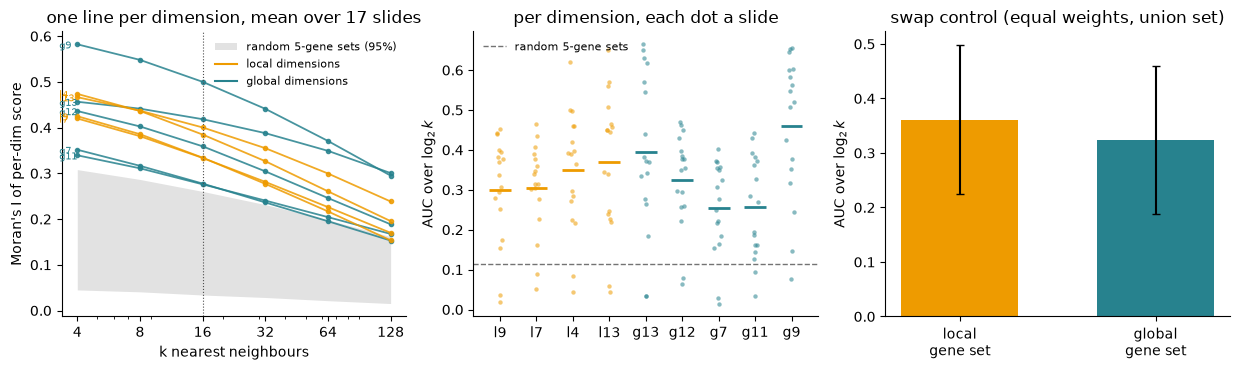

In [16]:
I_cols = [f"I_k{k}" for k in KS]
null_band = np.mean([res["control_I_band"] for res in per_slide.values()], axis=0)  # 3 x len(KS)
dim_mean = per_dim.groupby(["scale", "dim"])[I_cols + ["auc", "slope_local", "slope_global"]].mean()
dim_sd = per_dim.groupby(["scale", "dim"])["auc"].std()

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))

ax = axes[0]
ax.fill_between(KS, null_band[0], null_band[2], color="0.75", alpha=0.45, lw=0,
                label=f"random {TOP_N}-gene sets (95%)")
for (scale, e), row in dim_mean.iterrows():
    ax.plot(KS, row[I_cols].to_numpy(dtype=float), marker="o", ms=3, lw=1.3,
            color=GROUP_COLORS[scale], alpha=0.85)
    ax.annotate(f"{scale[0]}{e}", (KS[0], row[I_cols[0]]), textcoords="offset points",
                xytext=(-13, -3), fontsize=7, color=GROUP_COLORS[scale])
ax.axvline(K_SPLIT, color="0.3", lw=0.8, ls=":")
ax.plot([], [], color=GROUP_COLORS["local"], label="local dimensions")
ax.plot([], [], color=GROUP_COLORS["global"], label="global dimensions")
ax.set(xscale="log", xlabel="k nearest neighbours", ylabel="Moran's I of per-dim score",
       title=f"one line per dimension, mean over {len(SLIDES)} slides")
ax.set_xticks(KS); ax.set_xticklabels(KS)
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
order = [("local", e) for e in DIMS["local"]] + [("global", e) for e in DIMS["global"]]
for x, (scale, e) in enumerate(order):
    vals = per_dim.query("scale == @scale and dim == @e")["auc"]
    ax.scatter(np.full(len(vals), x) + np.random.default_rng(0).normal(0, 0.06, len(vals)),
               vals, s=10, color=GROUP_COLORS[scale], alpha=0.55, lw=0)
    ax.hlines(vals.mean(), x - 0.3, x + 0.3, color=GROUP_COLORS[scale], lw=2)
ax.axhline(np.mean([r["control_auc"]["mean"] for r in per_slide.values()]),
           color="0.45", ls="--", lw=1, label=f"random {TOP_N}-gene sets")
ax.set(xticks=range(len(order)), xticklabels=[f"{s[0]}{e}" for s, e in order],
       ylabel="AUC over $\\log_2 k$", title="per dimension, each dot a slide")
ax.legend(frameon=False, fontsize=8)

ax = axes[2]
swap = pd.DataFrame([res["swap_control"] for res in per_slide.values()])
ax.bar([0, 1], [swap["local_geneset_auc"].mean(), swap["global_geneset_auc"].mean()],
       yerr=[swap["local_geneset_auc"].std(), swap["global_geneset_auc"].std()],
       color=[GROUP_COLORS["local"], GROUP_COLORS["global"]], capsize=3, width=0.6)
ax.set(xticks=[0, 1], xticklabels=["local\ngene set", "global\ngene set"],
       ylabel="AUC over $\\log_2 k$", title="swap control (equal weights, union set)")

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "communication_score_moran.pdf", bbox_inches="tight")
fig.savefig(RESULTS_DIR / "communication_score_moran.png", dpi=200, bbox_inches="tight")
plt.show()

In [17]:
# Per-dimension summary, which is the table to read rather than the collapsed one.
dim_summary = dim_mean[["auc", "slope_local", "slope_global"]].copy()
dim_summary["auc_sd_over_slides"] = dim_sd
dim_summary["n_genes"] = [len(programs.query("scale == @s and dim == @e"))
                          for s, e in dim_summary.index]
dim_summary["genes"] = [", ".join(programs.query("scale == @s and dim == @e")["gene"])
                        for s, e in dim_summary.index]
dim_summary.round(3).to_csv(RESULTS_DIR / "dimension_summary.csv")
print(dim_summary.round(3).to_string())
print(f"\nspread WITHIN a scale (max-min of per-dim AUC): "
      f"local {dim_summary.loc['local','auc'].max() - dim_summary.loc['local','auc'].min():.3f}, "
      f"global {dim_summary.loc['global','auc'].max() - dim_summary.loc['global','auc'].min():.3f}")
print(f"difference BETWEEN scales (mean of per-dim AUC): "
      f"{dim_summary.loc['global','auc'].mean() - dim_summary.loc['local','auc'].mean():+.3f}")

              auc  slope_local  slope_global  auc_sd_over_slides  n_genes                                       genes
scale  dim                                                                                                           
global 7    0.256       -0.037        -0.041               0.118        5  Circ.CDR1, Circ.RMST, PTPRZ1, GLI3, ZSWIM8
       9    0.460       -0.041        -0.069               0.181        5              GLI3, IRX3, PTPRZ1, PAX6, DBX2
       11   0.257       -0.032        -0.036               0.128        5         IRX3, MAP2, CUL3, ZNF609, Circ.CDR1
       12   0.325       -0.039        -0.057               0.120        5          JUN, TUBB3, Circ.CDR1, JUNB, PTCH1
       13   0.395       -0.019        -0.039               0.200        5            NKX6.1, FOS, GLI1, JUNB, NEUROG2
local  4    0.349       -0.044        -0.063               0.151        5            NKX6.1, SOX2, PTCH1, KLF13, GLI3
       7    0.303       -0.043        -0.055            

## Controls, read out as numbers

In [18]:
ctrl = pd.DataFrame({
    "local_auc": l2.query("scale == 'local'").set_index("slide")["auc"],
    "global_auc": l2.query("scale == 'global'").set_index("slide")["auc"],
    "null_auc_mean": {s: r["control_auc"]["mean"] for s, r in per_slide.items()},
    "null_auc_p95": {s: r["control_auc"]["p95"] for s, r in per_slide.items()},
    "swap_local_geneset_auc": {s: r["swap_control"]["local_geneset_auc"] for s, r in per_slide.items()},
    "swap_global_geneset_auc": {s: r["swap_control"]["global_geneset_auc"] for s, r in per_slide.items()},
})
ctrl.to_csv(RESULTS_DIR / "controls_per_slide.csv")

print(ctrl.mean().round(3).to_string())
print(f"\nslides where the swap control follows the GENE SET (global set > local set): "
      f"{int((ctrl['swap_global_geneset_auc'] > ctrl['swap_local_geneset_auc']).sum())}/{len(ctrl)}")

# The comparison that matters now is per DIMENSION against the TOP_N-gene null, slide by slide.
nulls = pd.Series({s: r["control_auc"]["p95"] for s, r in per_slide.items()})
pd_ = per_dim.assign(null_p95=per_dim["slide"].map(nulls))
pd_["beats_null"] = pd_["auc"] > pd_["null_p95"]
beat = pd_.groupby(["scale", "dim"])["beats_null"].mean().mul(len(SLIDES)).round().astype(int)
print(f"\n(slide, dimension) pairs above the random {TOP_N}-gene 95th percentile: "
      f"{int(pd_['beats_null'].sum())}/{len(pd_)}")
print("per dimension, slides above the null:")
print("  " + ", ".join(f"{s[0]}{e}:{n}/{len(SLIDES)}" for (s, e), n in beat.items()))
best_per_slide = per_dim.loc[per_dim.groupby(["slide", "scale"])["auc"].idxmax()]
w = best_per_slide.pivot(index="slide", columns="scale", values="auc")
print(f"\nbest single dimension per slide: local {w['local'].mean():.3f}, "
      f"global {w['global'].mean():.3f}; global > local in "
      f"{int((w['global'] > w['local']).sum())}/{len(w)} slides")

local_auc                  0.239
global_auc                 0.262
null_auc_mean              0.115
null_auc_p95               0.226
swap_local_geneset_auc     0.361
swap_global_geneset_auc    0.324

slides where the swap control follows the GENE SET (global set > local set): 5/17

(slide, dimension) pairs above the random 5-gene 95th percentile: 124/153
per dimension, slides above the null:
  g7:10/17, g9:17/17, g11:11/17, g12:16/17, g13:13/17, l4:15/17, l7:15/17, l9:12/17, l13:15/17

best single dimension per slide: local 0.417, global 0.485; global > local in 15/17 slides


## Sensitivity to `TOP_N`

Each dimension's own score at N = 3, 5 and 10, on the three largest slides. If a dimension's
AUC moves a lot with N, its score is about the gene-set size and not about the program.

In [19]:
sens = []
for n in (3, 5, 10):
    for slide in slide_sizes.index[:3]:
        sub = adata[adata.obs[SAMPLE_KEY] == slide].copy()
        X = np.asarray(sub.layers[LAYER_KEY].todense()) if hasattr(sub.layers[LAYER_KEY], "todense") \
            else np.asarray(sub.layers[LAYER_KEY])
        Xz = M.zscore_expression(X)
        coords = np.asarray(sub.obsm["spatial"])
        for scale in ("local", "global"):
            S_dims, _ = M.score_dimensions(
                Xz, G[scale], DIMS[scale], n,
                rank=RANK[scale] if RANK_BY == "loading_x_sd" else None,
                gene_mask=DETECTED,
            )
            S_dims, _ = M.fix_orientation(S_dims, np.asarray(sub.obsm[f"{SEED}_{scale}_emb"])[:, DIMS[scale]])
            for j, e in enumerate(DIMS[scale]):
                I = M.multiscale_moran(coords, S_dims[:, j], KS)
                sens.append({"top_n": n, "slide": slide, "scale": scale, "dim": int(e),
                             **M.auc_local_index(I, KS)})
sens = pd.DataFrame(sens)
sens.to_csv(RESULTS_DIR / "sensitivity_top_n.csv", index=False)
print("AUC per dimension, mean over the 3 largest slides:")
print(sens.pivot_table(index=["scale", "dim"], columns="top_n", values="auc").round(3).to_string())

AUC per dimension, mean over the 3 largest slides:
top_n          3      5      10
scale  dim                     
global 7    0.328  0.309  0.207
       9    0.494  0.543  0.567
       11   0.361  0.368  0.157
       12   0.273  0.393  0.226
       13   0.506  0.550  0.160
local  4    0.513  0.454  0.398
       7    0.358  0.331  0.297
       9    0.362  0.405  0.236
       13   0.449  0.415  0.360


## Is a dimension a *communication* program?

The score is per-cell **program activity**, not a directional sender/receiver score. A
dimension earns the word "communication" only if its top-N genes are enriched for ligands and
receptors, tested against the panel as background (hypergeometric). With an 88-gene targeted
panel both the set and the background are small, so read the fold change and treat the p-value
as weak evidence.

In [20]:
lr_genes = None
try:
    import liana as li

    resource = li.resource.select_resource("consensus")
    lr_genes = set()
    for col in [c for c in resource.columns if "ligand" in c or "receptor" in c]:
        for entry in resource[col].dropna().astype(str):
            lr_genes.update(entry.split("_"))  # split complexes into subunits
    print(f"LIANA consensus: {len(lr_genes)} ligand/receptor gene symbols, "
          f"{len(lr_genes & set(adata.var_names))} of them in this {adata.n_vars}-gene panel")
except Exception as exc:  # resource unavailable (no network / no liana)
    print(f"skipping LR enrichment: {type(exc).__name__}: {exc}")

LIANA consensus: 1876 ligand/receptor gene symbols, 12 of them in this 88-gene panel


In [21]:
if lr_genes:
    ref = per_slide[SLIDES[0]]
    lr_rows = []
    for scale in ("local", "global"):
        for e, genes in ref[f"{scale}_genes"].items():
            lr_rows.append({"scale": scale, "dim": int(e),
                            **M.lr_enrichment(genes, lr_genes, adata.var_names.tolist()),
                            "lr_genes_in_set": ",".join(sorted(set(genes) & lr_genes)),
                            "genes": ",".join(genes)})
    lr_table = pd.DataFrame(lr_rows).sort_values(["scale", "pval"])
    lr_table.to_csv(RESULTS_DIR / "lr_enrichment_per_dimension.csv", index=False)
    print(lr_table[["scale", "dim", "overlap", "n_set", "expected", "fold", "pval",
                    "lr_genes_in_set"]].to_string(index=False))

 scale  dim  overlap  n_set  expected     fold     pval lr_genes_in_set
global   12        1      5  0.681818 1.466667 0.528411           PTCH1
global    7        1      5  0.681818 1.466667 0.528411          PTPRZ1
global    9        1      5  0.681818 1.466667 0.528411          PTPRZ1
global   13        0      5  0.681818 0.000000 1.000000                
global   11        0      5  0.681818 0.000000 1.000000                
 local    7        1      5  0.681818 1.466667 0.528411            HHIP
 local    4        1      5  0.681818 1.466667 0.528411           PTCH1
 local    9        0      5  0.681818 0.000000 1.000000                
 local   13        0      5  0.681818 0.000000 1.000000                


## The scores on the tissue

One map per informative dimension (orientation-fixed, so "positive" means the same thing in
every panel), on the two slides the figure config uses as examples.

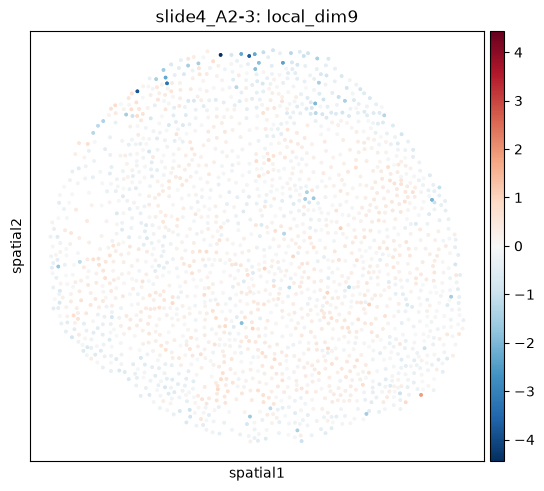

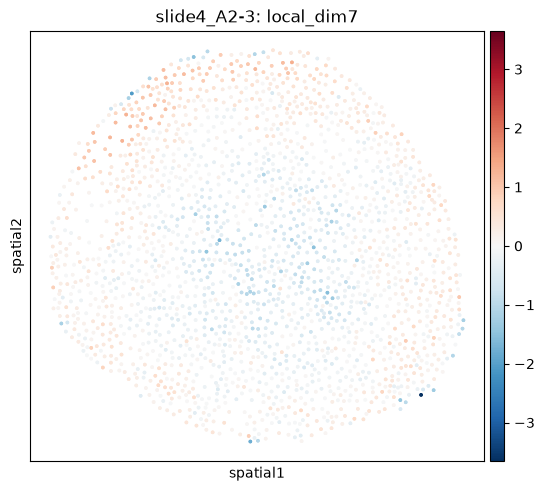

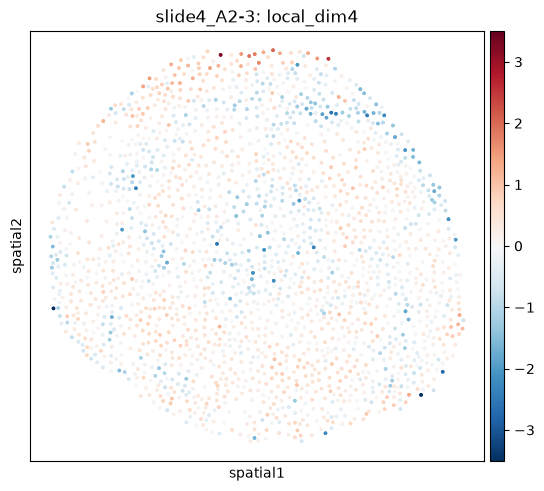

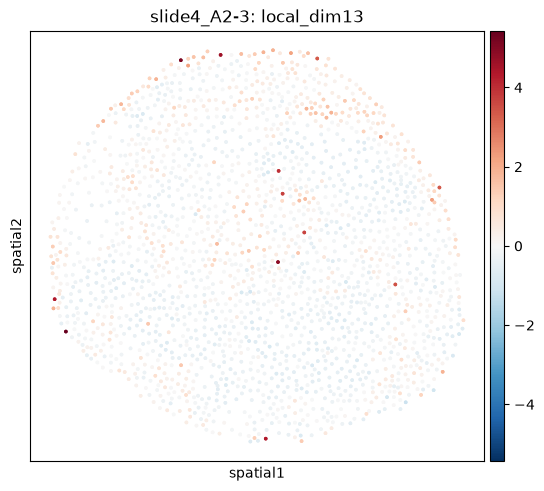

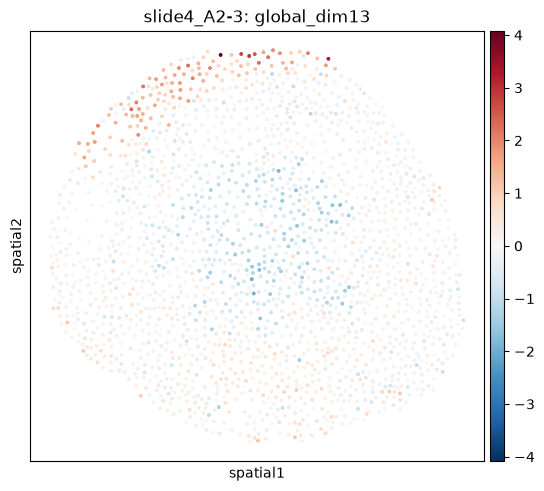

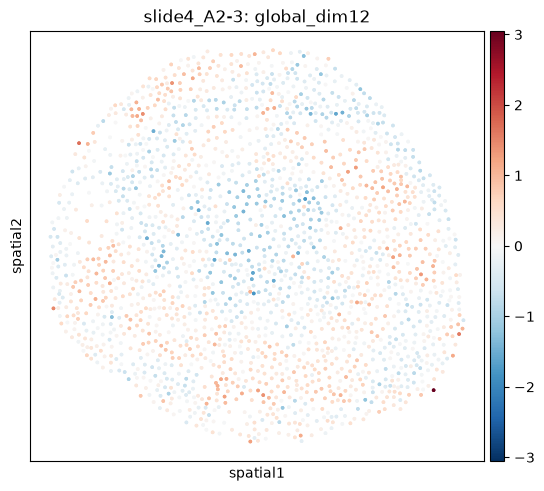

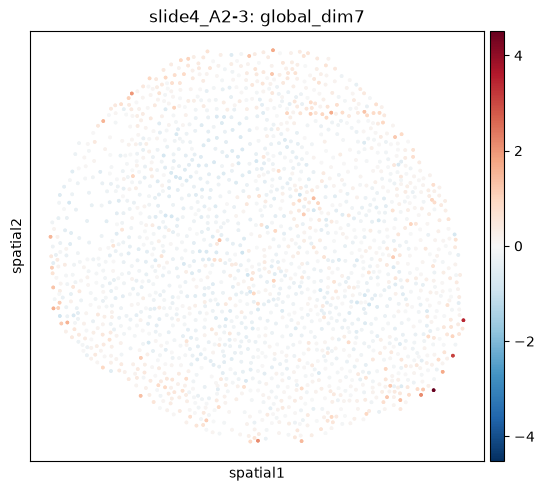

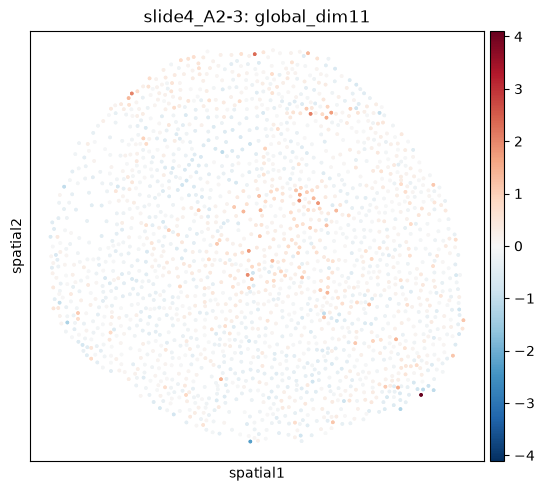

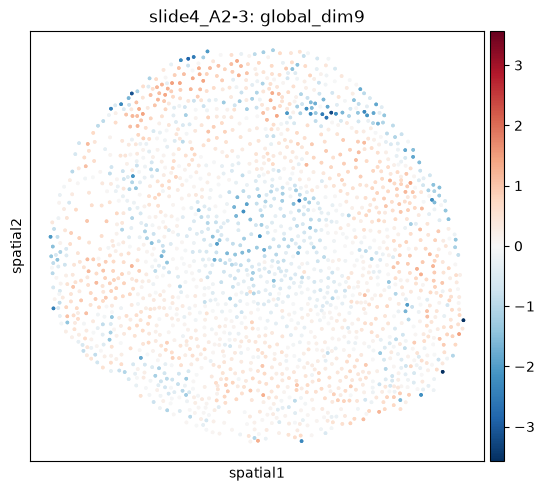

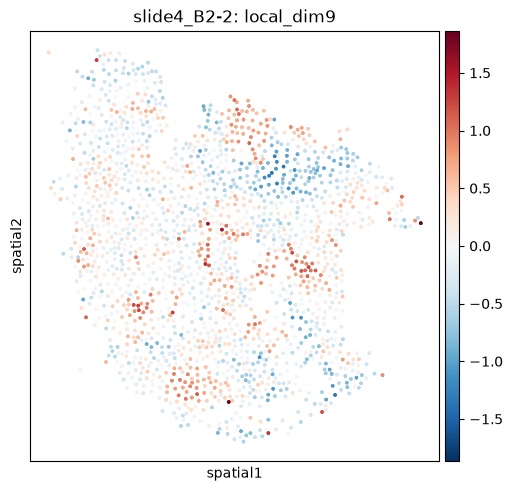

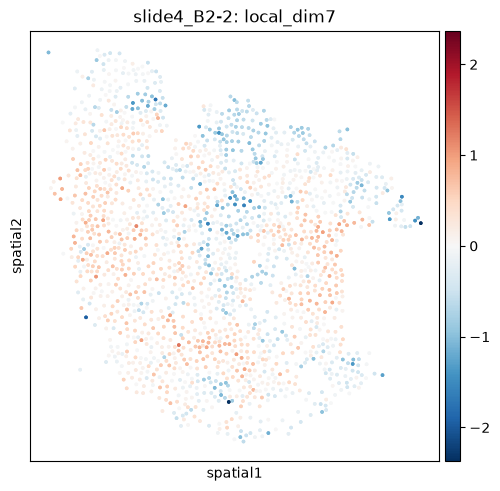

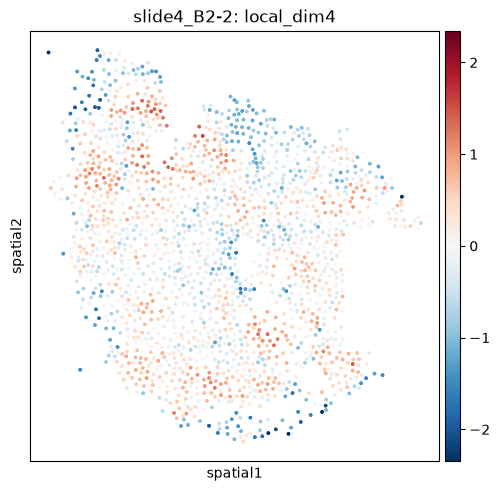

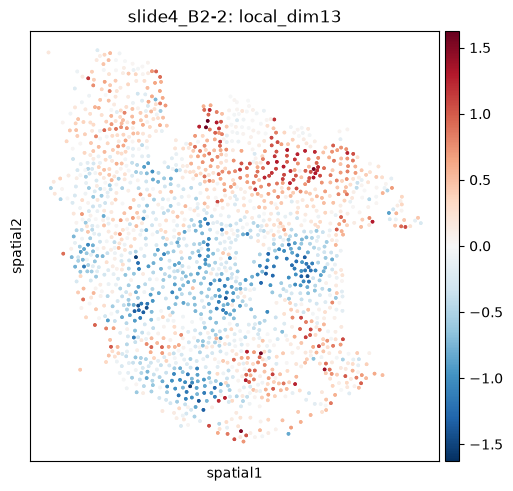

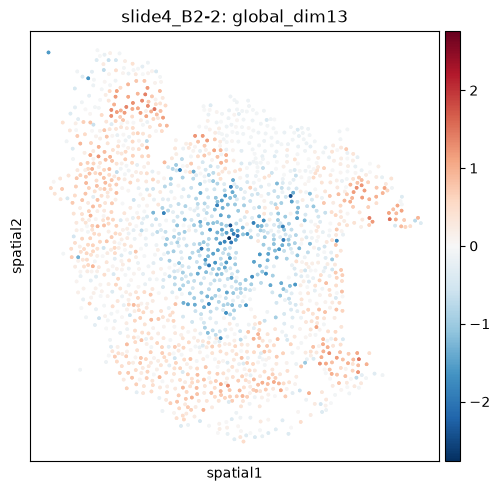

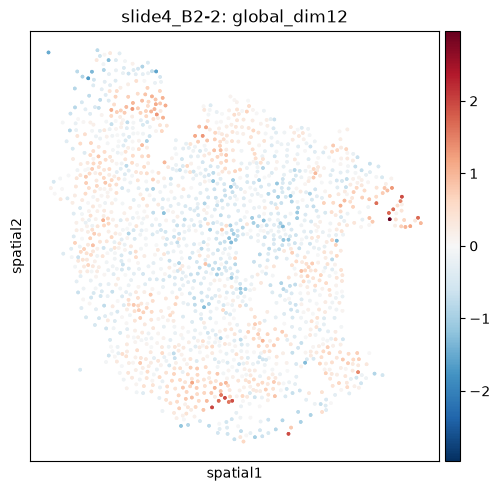

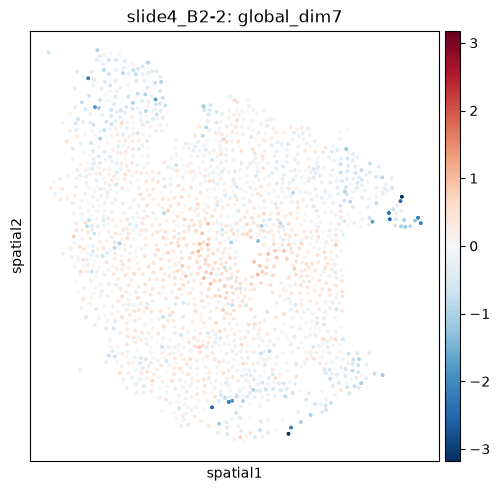

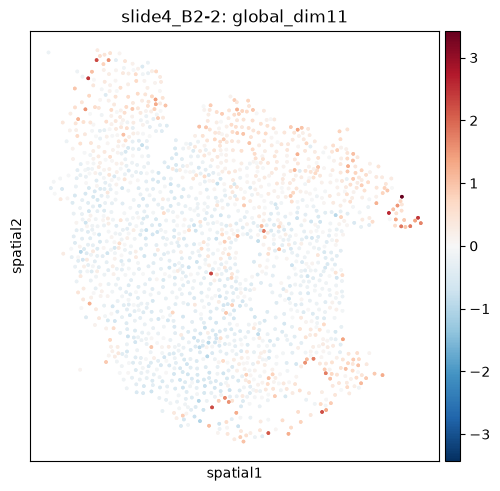

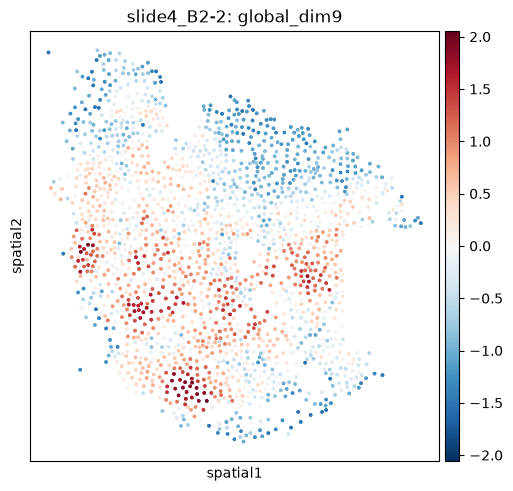

In [22]:
from matplotlib.colors import CenteredNorm

example_slides = [slides["Ctrl"], slides["SSH"]]
for slide in example_slides:
    view = adata[adata.obs[SAMPLE_KEY] == slide]
    for col in DIM_COLS:
        # A fresh CenteredNorm per panel: it autoscales on first use, so one shared instance
        # would carry the first panel's range into the next and the colours would not mean the
        # same thing. squidpy has no vcenter= of its own.
        sq.pl.spatial_scatter(
            view, spatial_key="spatial", library_key=SAMPLE_KEY, color=col,
            shape=None, size=10, cmap="RdBu_r", norm=CenteredNorm(),
            title=f"{slide}: {col.replace('commscore_', '')}",
        )

In [23]:
# Per-cell scores travel with the AnnData for anyone re-opening this analysis.
adata.obs[SCORE_COLS + [SAMPLE_KEY]].to_csv(RESULTS_DIR / "per_cell_scores.csv")
print("wrote:")
for p in sorted(RESULTS_DIR.iterdir()):
    print(" ", p.name)

wrote:
  communication_score_moran.pdf
  communication_score_moran.png
  condition_split.pdf
  condition_split.png
  controls_per_slide.csv
  d_half_by_condition.csv
  dimension_gene_programs.csv
  dimension_summary.csv
  distance_profiles_slide4_A2-3.png
  distance_profiles_slide4_B2-2.png
  gene_decay_local_vs_global.pdf
  gene_decay_local_vs_global.png
  gene_decay_vs_distance.csv
  graft_distance_local_dim13_per_gene.png
  high_vs_low_score_contrast.pdf
  high_vs_low_score_contrast.png
  high_vs_low_score_gene_contrast.csv
  lr_enrichment_per_dimension.csv
  model_40_performance.csv
  moran_curves_per_slide.csv
  moran_per_dimension.csv
  per_cell_scores.csv
  sensitivity_top_n.csv
  shared_genes_by_dimension.csv


# What the score is made of, and how fast it varies in space

Two questions the Moran's I curves do not answer.

**What is the program?** A dimension is a *combination* of genes with signs, not a gene list.
`local 9` and `global 9` share no genes here, but `NKX6.1` is in three local dimensions and one
global one, and `IRX3` enters `local 13` negatively and `global 9` positively. A gene appearing
in two dimensions is not redundancy — what separates the programs is which genes travel
together and which way each one points. The contrast below makes that readable: for each
dimension, how much each gene moves between the cells with the **highest** score and the cells
with the **lowest**.

**How fast does it vary?** The anchor construction from `4_b_decoder_interpretablity.ipynb`,
but anchored on the **communication score** rather than on the raw embedding dimension:
high-score cells that form a spatial focus become the anchor, every cell gets a signed distance
to that focus's border, and each gene is profiled against it. The question is whether the genes
behind a local dimension finish changing sooner than the genes behind a global one.

In [24]:
from interscale.pl import distance_profile
from interscale.tl import (
    anchor_signed_distance,
    find_anchor_cells,
    local_reach_um,
    profile_by_distance,
)

# num_layers message-passing hops over a radius-`radius` graph: a hard bound on how far a cell's
# own expression can travel through the local component. Anything changing beyond it is out of
# every cell's neighbourhood, not just the average one.
REACH = local_reach_um(cfg)
QUANTILE = 0.95       # per-slide tail the anchor is taken from
MIN_CLUSTER_SIZE = 8  # drops scattered high-score cells, which carry no location to measure from
print(f"local component reach: {REACH:.0f} um "
      f"({cfg.dataset.spatial_neigbors_kwargs.radius} um x "
      f"{cfg.model.local_component.parameters.num_layers} hops)")

# find_anchor_cells reads adata.obsm[key][:, column], so the per-dimension scores have to be back
# on the full object as a matrix. COLUMN[scale][e] maps a dimension id to its column.
for scale in ("local", "global"):
    adata.obsm[f"commscore_{scale}"] = adata.obs[
        [f"commscore_{scale}_dim{e}" for e in DIMS[scale]]
    ].to_numpy()
COLUMN = {s: {e: j for j, e in enumerate(DIMS[s])} for s in ("local", "global")}

local component reach: 400 um (200 um x 2 hops)


## A. What distinguishes the programs: the same genes, different combinations and signs

Per slide, cells are split at the top and bottom decile of each dimension's score and the genes
are compared between them in z-units (within slide, the scale the score itself is built on),
then averaged over slides. A dot marks the genes that dimension's score is actually built from.

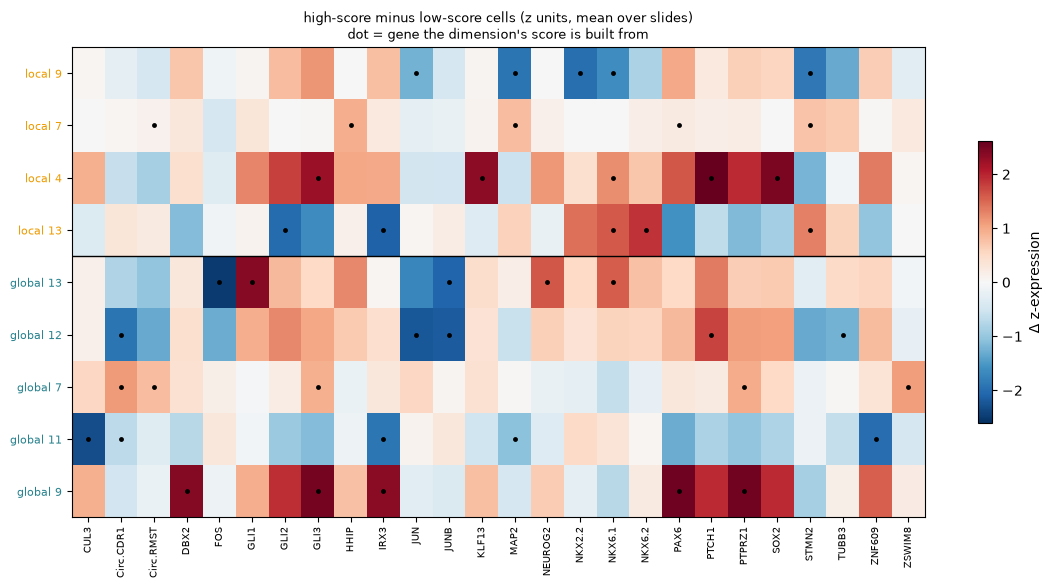

In [25]:
QTOP, QBOT = 0.90, 0.10
all_genes = sorted(set(gene_sets["local"]) | set(gene_sets["global"]))
gi = [adata.var_names.get_loc(g) for g in all_genes]

delta = {}
for scale in ("local", "global"):
    for e in DIMS[scale]:
        per_slide_delta = []
        for slide in SLIDES:
            m = (adata.obs[SAMPLE_KEY] == slide).to_numpy()
            Xs = X_all[m][:, gi]
            Xs = (Xs - Xs.mean(0)) / np.where(Xs.std(0) == 0, 1.0, Xs.std(0))
            s = adata.obs.loc[m, f"commscore_{scale}_dim{e}"].to_numpy()
            hi, lo = s >= np.quantile(s, QTOP), s <= np.quantile(s, QBOT)
            per_slide_delta.append(Xs[hi].mean(0) - Xs[lo].mean(0))
        delta[(scale, e)] = np.mean(per_slide_delta, axis=0)

D = pd.DataFrame(delta, index=all_genes).T
D.index = pd.MultiIndex.from_tuples(D.index, names=["scale", "dim"])
D.round(3).to_csv(RESULTS_DIR / "high_vs_low_score_gene_contrast.csv")

fig, ax = plt.subplots(figsize=(0.33 * len(all_genes) + 3.0, 0.42 * len(D) + 2.2))
v = float(np.abs(D.to_numpy()).max())
im = ax.imshow(D.to_numpy(), cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
for y, (scale, e) in enumerate(D.index):
    sel = set(programs.query("scale == @scale and dim == @e")["gene"])
    for x, g in enumerate(all_genes):
        if g in sel:
            ax.plot(x, y, marker="o", ms=3.5, color="k", mew=0)
ax.set_xticks(range(len(all_genes)))
ax.set_xticklabels(all_genes, rotation=90, fontsize=7)
ax.set_yticks(range(len(D)))
ax.set_yticklabels([f"{s} {e}" for s, e in D.index], fontsize=8)
for y, (scale, _) in enumerate(D.index):
    ax.get_yticklabels()[y].set_color(GROUP_COLORS[scale])
ax.axhline(len(DIMS["local"]) - 0.5, color="k", lw=1)
ax.set_title("high-score minus low-score cells (z units, mean over slides)\n"
             "dot = gene the dimension's score is built from", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.6, label="$\\Delta$ z-expression")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "high_vs_low_score_contrast.pdf", bbox_inches="tight")
fig.savefig(RESULTS_DIR / "high_vs_low_score_contrast.png", dpi=200, bbox_inches="tight")
plt.show()

In [26]:
# The same point as a number: genes shared between a local and a global dimension, and whether
# they point the same way in both. A shared gene with opposite signs is two different programs.
shared = sorted(set(gene_sets["local"]) & set(gene_sets["global"]))
rows = []
for g in shared:
    for scale in ("local", "global"):
        for e in DIMS[scale]:
            p = programs.query("scale == @scale and dim == @e and gene == @g")
            if len(p):
                rows.append({"gene": g, "scale": scale, "dim": int(e),
                             "weight": float(p["weight"].iloc[0]),
                             "delta_high_minus_low": float(D.loc[(scale, e), g])})
shared_tab = pd.DataFrame(rows)
shared_tab.to_csv(RESULTS_DIR / "shared_genes_by_dimension.csv", index=False)
for g, grp in shared_tab.groupby("gene"):
    signs = ", ".join(f"{r.scale[0]}{r.dim}:{r.weight:+.2f}" for r in grp.itertuples())
    flips = grp["weight"].gt(0).nunique() > 1
    print(f"{g:11s} {signs}{'   <- sign flips between dimensions' if flips else ''}")

Circ.RMST   l7:+0.16, g7:+0.17
GLI3        l4:+0.19, g7:+0.17, g9:+0.22
IRX3        l13:-0.20, g11:-0.18, g9:+0.20   <- sign flips between dimensions
JUN         l9:-0.24, g12:-0.21
MAP2        l9:-0.19, l7:+0.23, g11:-0.19   <- sign flips between dimensions
NKX6.1      l9:-0.18, l4:+0.16, l13:+0.14, g13:+0.13   <- sign flips between dimensions
PAX6        l7:+0.15, g9:+0.16
PTCH1       l4:+0.21, g12:+0.17


## B. Anchoring on the score, and profiling the genes against distance

`find_anchor_cells` with `sign='+'`: the scores are orientation-fixed, so the positive pole is
the program-active one and "high communication score" is a well-defined end. Anchors are found
per slide, because each slide is its own coordinate system and its own graph.

In [27]:
anchors, dists = {}, {}
for scale in ("local", "global"):
    for e in DIMS[scale]:
        key = f"commscore_{scale}_dim{e}"
        a, f = find_anchor_cells(
            adata, f"commscore_{scale}", COLUMN[scale][e],
            sample_key=SAMPLE_KEY, quantile=QUANTILE, sign="+",
            link_radius=REACH, min_cluster_size=MIN_CLUSTER_SIZE,
            samples=SLIDES, key_added=f"{key}_anchor",
        )
        anchors[(scale, e)] = (a, f)
        dists[(scale, e)] = anchor_signed_distance(
            adata, a, sample_key=SAMPLE_KEY, samples=SLIDES, key_added=f"{key}_dist"
        )
        n_slides = int(adata.obs.loc[a, SAMPLE_KEY].nunique())
        print(f"{scale:6s} dim {e:2d}: {int(a.sum()):4d} anchor cells, "
              f"{n_slides}/{len(SLIDES)} slides with a focus")

local  dim  9: 1358 anchor cells, 17/17 slides with a focus


local  dim  7: 1519 anchor cells, 17/17 slides with a focus
local  dim  4: 1457 anchor cells, 17/17 slides with a focus


local  dim 13: 1514 anchor cells, 17/17 slides with a focus


global dim 13: 1682 anchor cells, 17/17 slides with a focus
global dim 12: 1274 anchor cells, 17/17 slides with a focus


global dim  7: 1517 anchor cells, 17/17 slides with a focus


global dim 11: 1374 anchor cells, 17/17 slides with a focus
global dim  9: 1789 anchor cells, 17/17 slides with a focus


In [28]:
# Per gene, per dimension, per slide: how far out the gene has got through its total change.
decay = []
for (scale, e), dist in dists.items():
    genes = programs.query("scale == @scale and dim == @e")["gene"].tolist()
    for slide in SLIDES:
        prof = profile_by_distance(
            adata, genes, dist, layer=LAYER_KEY,
            mask=(adata.obs[SAMPLE_KEY] == slide).to_numpy(),
            n_bins=14, min_cells=15, binning="quantile",
        )
        if prof.empty:
            continue
        st = M.profile_decay_stats(prof, local_reach=REACH)
        decay.append(st.assign(scale=scale, dim=int(e), slide=slide))
decay = pd.concat(decay, ignore_index=True)
# Geometry control: a dimension whose anchor is small or central leaves a shorter distance axis,
# so a short d_half could be the anchor rather than the gene. d_half_frac removes that.
decay["d_half_frac"] = decay["d_half"] / decay["d_max"]
decay.to_csv(RESULTS_DIR / "gene_decay_vs_distance.csv", index=False)
print(f"{len(decay)} (gene, dimension, slide) profiles; "
      f"{int(decay['flat'].sum())} too flat to measure a decay on")
print("\ndistance axis available per scale (d_max, um) -- if these differ, read d_half_frac:")
print(decay.groupby("scale")["d_max"].agg(["median", "mean"]).round(0).to_string())

765 (gene, dimension, slide) profiles; 123 too flat to measure a decay on

distance axis available per scale (d_max, um) -- if these differ, read d_half_frac:
        median    mean
scale                 
global  2397.0  2637.0
local   2272.0  2442.0


### The profiles themselves, on the two example slides

One panel per dimension, its own genes overlaid, each rescaled 0-1 from the anchor border to
the far end so the *shape* is comparable between genes. The dashed line is the local
component's reach: a curve still climbing to the right of it is changing over a distance no
cell's neighbourhood spans.

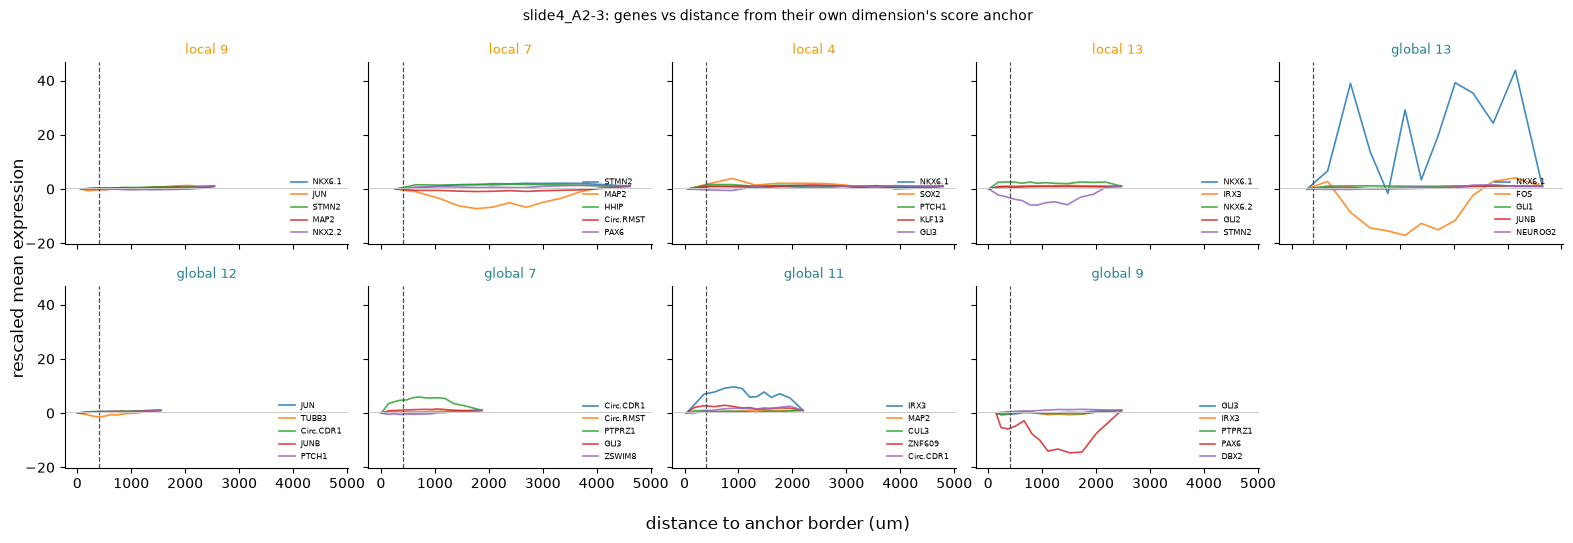

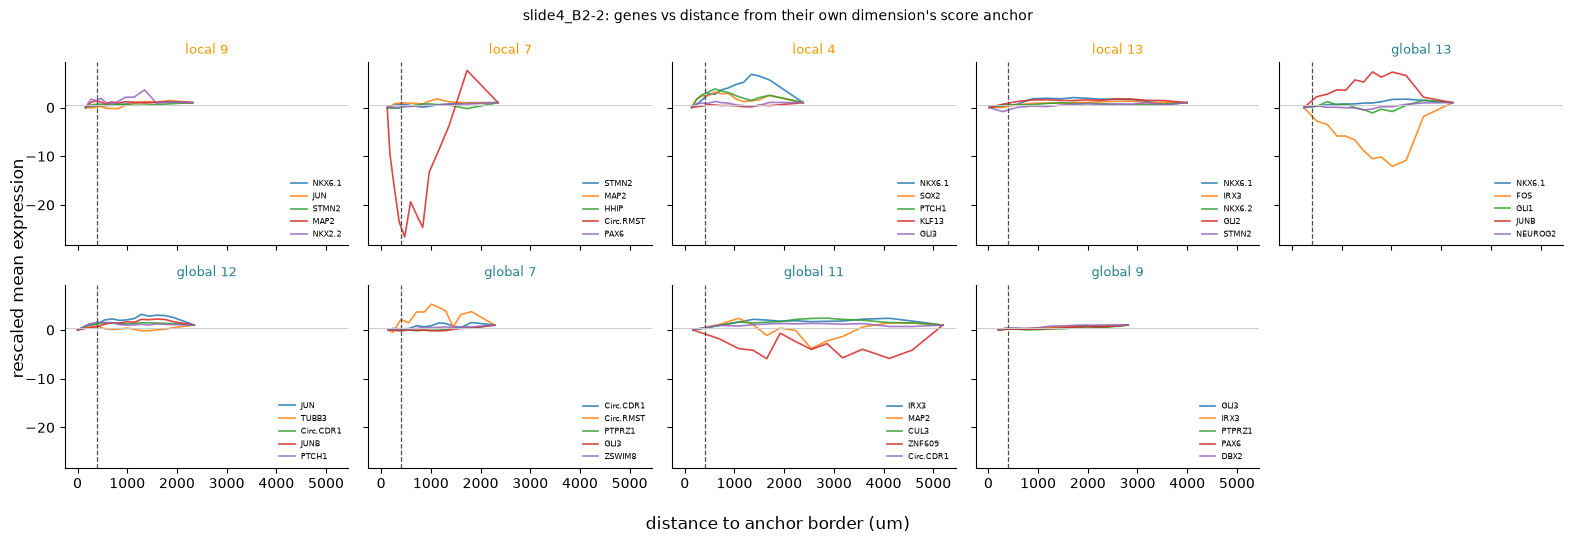

In [29]:
for slide in example_slides:
    order = [("local", e) for e in DIMS["local"]] + [("global", e) for e in DIMS["global"]]
    fig, axes = plt.subplots(2, 5, figsize=(16, 5.4), sharex=True, sharey=True)
    for ax, (scale, e) in zip(axes.ravel(), order):
        genes = programs.query("scale == @scale and dim == @e")["gene"].tolist()
        prof = profile_by_distance(
            adata, genes, dists[(scale, e)], layer=LAYER_KEY,
            mask=(adata.obs[SAMPLE_KEY] == slide).to_numpy(),
            n_bins=14, min_cells=15, binning="quantile",
        )
        if prof.empty:
            ax.set_title(f"{scale} {e}: no focus", fontsize=8, color="0.5")
            ax.axis("off")
            continue
        for gene, g in prof.groupby("gene", sort=False):
            g = g[g["center"] >= 0].sort_values("center")
            v = g["mean"].to_numpy(float)
            rng_ = v[-1] - v[0]
            if abs(rng_) < 1e-12:
                continue
            ax.plot(g["center"], (v - v[0]) / rng_, lw=1.2, alpha=0.85, label=gene)
        ax.axvline(REACH, color="0.3", ls="--", lw=0.9)
        ax.axhline(0.5, color="0.8", lw=0.7)
        ax.set_title(f"{scale} {e}", fontsize=9, color=GROUP_COLORS[scale])
        ax.legend(fontsize=5.5, frameon=False, loc="lower right", ncol=1)
        ax.spines[["top", "right"]].set_visible(False)
    for ax in axes.ravel()[len(order):]:
        ax.axis("off")
    fig.supxlabel("distance to anchor border (um)")
    fig.supylabel("rescaled mean expression")
    fig.suptitle(f"{slide}: genes vs distance from their own dimension's score anchor", fontsize=10)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"distance_profiles_{slide}.png", dpi=200, bbox_inches="tight")
    plt.show()

## C. The answer as a number: do local programs finish changing sooner?

`d_half` is the distance at which a gene has completed half its change away from the anchor.
Small = varies rapidly in space. The comparison is local-dimension genes against
global-dimension genes, with the local component's reach marked.

62% of measurable profiles are non-monotonic; excluded from d_half
scale
global    0.602
local     0.653


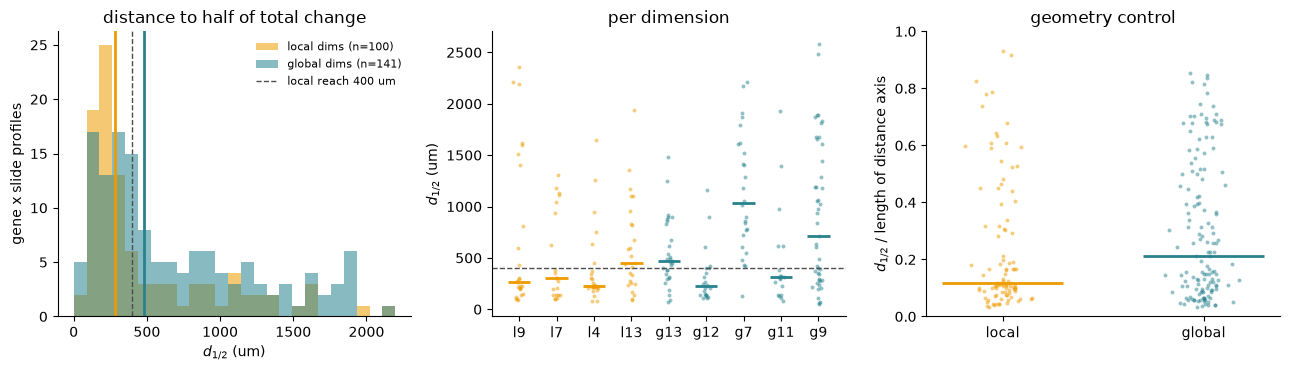

In [30]:
# A third to a half of the profiles wander rather than decay (they overshoot their own
# endpoint and come back), and d_half is an arbitrary crossing for those. Keeping them pulled
# the two scales' medians together, so the headline uses monotonic profiles only -- and the
# fraction that are NOT monotonic is itself a result, reported below.
nonmono_rate = 1 - decay.query("not flat")["monotonic"].mean()
print(f"{nonmono_rate:.0%} of measurable profiles are non-monotonic; excluded from d_half")
print(decay.query("not flat").groupby("scale")["monotonic"]
      .apply(lambda s: 1 - s.mean()).round(3).to_string())
ok = decay.query("not flat and monotonic").dropna(subset=["d_half"])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

ax = axes[0]
for i, scale in enumerate(("local", "global")):
    v = ok.query("scale == @scale")["d_half"]
    ax.hist(v, bins=np.linspace(0, ok["d_half"].quantile(0.98), 26), alpha=0.55,
            color=GROUP_COLORS[scale], label=f"{scale} dims (n={len(v)})")
    ax.axvline(v.median(), color=GROUP_COLORS[scale], lw=2)
ax.axvline(REACH, color="0.3", ls="--", lw=1, label=f"local reach {REACH:.0f} um")
ax.set(xlabel="$d_{1/2}$ (um)", ylabel="gene x slide profiles",
       title="distance to half of total change")
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
order = [("local", e) for e in DIMS["local"]] + [("global", e) for e in DIMS["global"]]
med = ok.groupby(["scale", "dim"])["d_half"].median()
for x, (scale, e) in enumerate(order):
    v = ok.query("scale == @scale and dim == @e")["d_half"]
    ax.scatter(np.full(len(v), x) + np.random.default_rng(0).normal(0, 0.07, len(v)), v,
               s=8, alpha=0.5, color=GROUP_COLORS[scale], lw=0)
    if len(v):
        ax.hlines(v.median(), x - 0.3, x + 0.3, color=GROUP_COLORS[scale], lw=2)
ax.axhline(REACH, color="0.3", ls="--", lw=1)
ax.set(xticks=range(len(order)), xticklabels=[f"{s[0]}{e}" for s, e in order],
       ylabel="$d_{1/2}$ (um)", title="per dimension")

ax = axes[2]
# d_half as a fraction of the distance axis each profile actually had: the geometry-free
# version, in case the two scales' anchors leave different amounts of room.
for i, scale in enumerate(("local", "global")):
    v = ok.query("scale == @scale")["d_half_frac"]
    ax.scatter(np.full(len(v), i) + np.random.default_rng(1).normal(0, 0.07, len(v)), v,
               s=8, alpha=0.5, color=GROUP_COLORS[scale], lw=0)
    ax.hlines(v.median(), i - 0.3, i + 0.3, color=GROUP_COLORS[scale], lw=2)
ax.set(xticks=[0, 1], xticklabels=["local", "global"], ylim=(0, 1),
       ylabel="$d_{1/2}$ / length of distance axis",
       title="geometry control")

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "gene_decay_local_vs_global.pdf", bbox_inches="tight")
fig.savefig(RESULTS_DIR / "gene_decay_local_vs_global.png", dpi=200, bbox_inches="tight")
plt.show()

In [31]:
from scipy.stats import mannwhitneyu

summ = ok.groupby("scale")["d_half"].agg(["median", "mean", "count"]).round(1)
print(summ.to_string())
u, p = mannwhitneyu(ok.query("scale == 'local'")["d_half"],
                    ok.query("scale == 'global'")["d_half"], alternative="less")
print(f"\nlocal d_half < global d_half (Mann-Whitney, profiles pooled): U={u:.0f}, p={p:.3g}")
print("  NOTE profiles from the same slide are not independent; read this as a descriptive"
      " effect size, not a test.")
print("\nper-dimension median d_half (um):")
print(med.round(0).to_string())

frac = ok.groupby("scale")["d_half_frac"].median()
uf, pf = mannwhitneyu(ok.query("scale == 'local'")["d_half_frac"],
                      ok.query("scale == 'global'")["d_half_frac"], alternative="less")
print(f"\ngeometry control -- d_half as a fraction of the available axis: "
      f"local {frac.get('local', float('nan')):.3f}, global {frac.get('global', float('nan')):.3f} "
      f"(p={pf:.3g})")
fb = decay.dropna(subset=["frac_beyond_reach"])
fbm = fb.groupby("scale")["frac_beyond_reach"].median()
print(f"median fraction of change beyond {REACH:.0f} um: "
      f"local {fbm.get('local', float('nan')):.3f}, global {fbm.get('global', float('nan')):.3f}")

        median   mean  count
scale                       
global   483.1  721.9    141
local    283.4  538.2    100

local d_half < global d_half (Mann-Whitney, profiles pooled): U=5450, p=0.00135
  NOTE profiles from the same slide are not independent; read this as a descriptive effect size, not a test.

per-dimension median d_half (um):
scale   dim
global  7      1036.0
        9       718.0
        11      310.0
        12      224.0
        13      466.0
local   4       224.0
        7       301.0
        9       269.0
        13      452.0

geometry control -- d_half as a fraction of the available axis: local 0.118, global 0.214 (p=0.0168)
median fraction of change beyond 400 um: local 0.310, global 0.353


# Does mixing SHH-grafted and control organoids hide the signal?

11 of the 17 slides are SHH-grafted, 6 are controls. If a program only exists where there is a
graft, pooling all slides averages a real effect against six slides that have nothing to show —
so the question is worth asking of every number above.

Everything needed is already per slide, so this is a grouping, not a recomputation. Two
separate questions get separate answers below:

1. **Does it rescue the local-vs-global separation?** No — and stratifying makes it slightly
   worse, not better.
2. **Does any individual program behave differently with a graft?** Yes, and that is the result
   worth pursuing.

In [32]:
CONDITION = adata.obs.groupby(SAMPLE_KEY, observed=True)["condition"].agg(lambda s: s.iloc[0])
print(CONDITION.value_counts().to_string())

per_dim["condition"] = per_dim["slide"].map(CONDITION)
decay["condition"] = decay["slide"].map(CONDITION)

print("\nMoran's I AUC (median over slide x dimension), local vs global WITHIN each condition:")
print(per_dim.groupby(["condition", "scale"])["auc"].median().round(3).to_string())

# Whether a program HAS a coherent gradient at all is the sharper condition read-out: a
# non-monotonic profile means there was no gradient to measure, only noise.
print("\nfraction of measurable profiles that are non-monotonic (= no coherent gradient):")
print(decay.query("not flat").groupby(["condition", "scale"])["monotonic"]
      .apply(lambda s: 1 - s.mean()).round(3).to_string())
print("\nsame, for the dimension with the largest condition effect:")
print(decay.query("not flat").groupby(["condition", "scale", "dim"])["monotonic"]
      .apply(lambda s: round(1 - s.mean(), 3)).unstack(0).to_string())

condition
SHH     11
Ctrl     6

Moran's I AUC (median over slide x dimension), local vs global WITHIN each condition:
condition  scale 
Ctrl       global    0.302
           local     0.302
SHH        global    0.356
           local     0.377

fraction of measurable profiles that are non-monotonic (= no coherent gradient):
condition  scale 
Ctrl       global    0.691
           local     0.716
SHH        global    0.554
           local     0.618

same, for the dimension with the largest condition effect:
condition    Ctrl    SHH
scale  dim              
global 7    0.667  0.622
       9    0.815  0.245
       11   0.760  0.733
       12   0.680  0.682
       13   0.474  0.545
local  4    0.769  0.562
       7    0.885  0.571
       9    0.640  0.633
       13   0.560  0.702


### 1. The local/global separation is not being hidden by the mixing

Within controls the two scales are identical; within SHH slides the *local* dimensions are
marginally ahead. Pooling was not masking a separation — there is none in either condition,
which is a cleaner negative than the pooled version and worth stating as such.

### 2. One program does change with the graft

Slide-level median `d_half` per dimension, controls against SHH. Slide level, not profile
level, because the slide is the experimental unit here.

In [33]:
from scipy.stats import mannwhitneyu

sl = (decay.query("not flat and monotonic").dropna(subset=["d_half"])
      .groupby(["scale", "dim", "slide"])["d_half"].median().reset_index())
sl["condition"] = sl["slide"].map(CONDITION)

rows = []
for (scale, e), g in sl.groupby(["scale", "dim"]):
    c = g.query("condition == 'Ctrl'")["d_half"]
    s_ = g.query("condition == 'SHH'")["d_half"]
    u, p = mannwhitneyu(s_, c, alternative="greater")
    rows.append({"scale": scale, "dim": int(e), "Ctrl": c.median(), "SHH": s_.median(),
                 "ratio": s_.median() / c.median(), "p_one_sided": p,
                 "n_Ctrl": len(c), "n_SHH": len(s_)})
cond_tab = pd.DataFrame(rows).sort_values("p_one_sided")
cond_tab.to_csv(RESULTS_DIR / "d_half_by_condition.csv", index=False)
print(cond_tab.round(3).to_string(index=False))
print(f"\nNOTE 9 dimensions were tested. Bonferroni-corrected, the smallest p above is "
      f"{cond_tab['p_one_sided'].min() * len(cond_tab):.2f} -- nothing here survives correction "
      f"on 6 vs 11 slides. Treat it as a hypothesis to test on more slides, not a result.")

 scale  dim     Ctrl      SHH  ratio  p_one_sided  n_Ctrl  n_SHH
 local   13  251.399  599.322  2.384        0.004       6      9
global    9  319.040  840.245  2.634        0.039       4     11
 local    4  290.181  223.945  0.772        0.259       5      9
 local    7  300.929  544.327  1.809        0.287       3     10
global    7 1046.885 1374.730  1.313        0.413       4      9
global   13  410.962  490.216  1.193        0.418       6      7
 local    9  532.818  247.196  0.464        0.467       4      8
global   12  207.956  218.111  1.049        0.643       3      6
global   11  374.991  301.955  0.805        0.669       5      6

NOTE 9 dimensions were tested. Bonferroni-corrected, the smallest p above is 0.03 -- nothing here survives correction on 6 vs 11 slides. Treat it as a hypothesis to test on more slides, not a result.


### An independent distance axis: distance to the SHH source

The anchors above are built from the score whose genes are then profiled. `dist_to_SHH` is not:
it comes from the data, is a physical distance in um, and means the same thing on every slide.
Profiling the genes against it is therefore an independent check of whether a program really
varies over a long distance in grafted organoids and not in controls.

Expression is z-scored **within slide** before pooling slides of one condition, so a slide's
overall expression level cannot shift a bin mean.

dist_to_SHH: 0-8028 um, 0 nan
profiling local dim 13: ['NKX6.1', 'IRX3', 'NKX6.2', 'GLI2', 'STMN2']


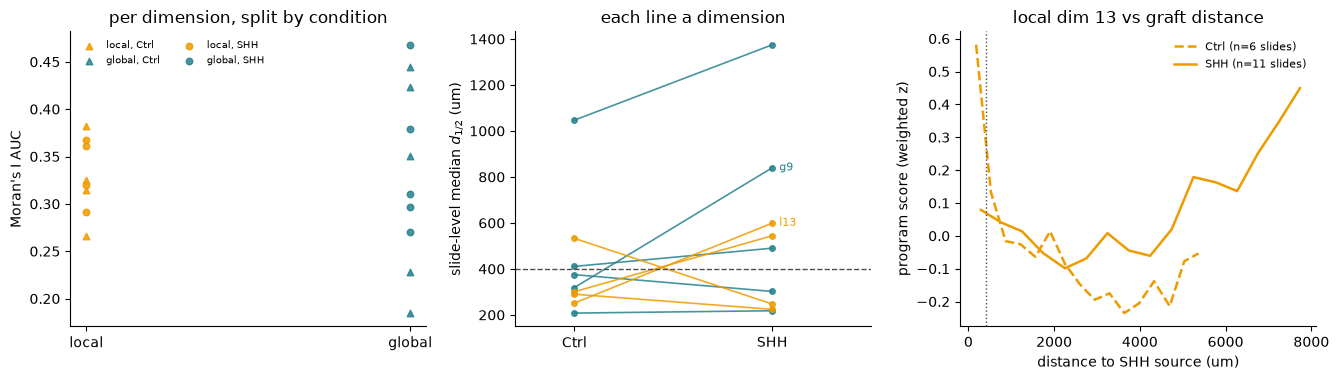

In [34]:
Z = np.zeros_like(X_all)
for slide in SLIDES:
    m = (adata.obs[SAMPLE_KEY] == slide).to_numpy()
    xs = X_all[m]
    Z[m] = (xs - xs.mean(0)) / np.where(xs.std(0) == 0, 1.0, xs.std(0))
adata.layers["_z_within_slide"] = Z

dist_shh = adata.obs["dist_to_SHH"].to_numpy(dtype=float)
cond_of_cell = adata.obs[SAMPLE_KEY].map(CONDITION).to_numpy()
print(f"dist_to_SHH: {np.nanmin(dist_shh):.0f}-{np.nanmax(dist_shh):.0f} um, "
      f"{int(np.isnan(dist_shh).sum())} nan")

# The dimension the condition table puts first, profiled against the graft distance.
TOP_SCALE, TOP_DIM = cond_tab.iloc[0]["scale"], int(cond_tab.iloc[0]["dim"])
top_genes = programs.query("scale == @TOP_SCALE and dim == @TOP_DIM")["gene"].tolist()
print(f"profiling {TOP_SCALE} dim {TOP_DIM}: {top_genes}")

shh_profiles = {}
for c in ("Ctrl", "SHH"):
    shh_profiles[c] = profile_by_distance(
        adata, top_genes, dist_shh, layer="_z_within_slide",
        mask=(cond_of_cell == c), n_bins=16, min_cells=40, binning="equal",
    )

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))

ax = axes[0]
for c, ls in (("Ctrl", "--"), ("SHH", "-")):
    sub_ = per_dim.query("condition == @c")
    for scale in ("local", "global"):
        v = sub_.query("scale == @scale").groupby("dim")["auc"].mean()
        ax.scatter([0 if scale == "local" else 1] * len(v), v, s=22,
                   color=GROUP_COLORS[scale], alpha=0.85,
                   marker="o" if c == "SHH" else "^",
                   label=f"{scale}, {c}")
ax.set(xticks=[0, 1], xticklabels=["local", "global"], ylabel="Moran's I AUC",
       title="per dimension, split by condition")
ax.legend(frameon=False, fontsize=7, ncol=2)

ax = axes[1]
for i, r in enumerate(cond_tab.sort_values(["scale", "dim"]).itertuples()):
    col = GROUP_COLORS[r.scale]
    ax.plot([0, 1], [r.Ctrl, r.SHH], color=col, lw=1.2, marker="o", ms=4, alpha=0.85)
    if r.p_one_sided < 0.05:
        ax.annotate(f"{r.scale[0]}{r.dim}", (1, r.SHH), textcoords="offset points",
                    xytext=(5, -2), fontsize=8, color=col)
ax.axhline(REACH, color="0.3", ls="--", lw=1)
ax.set(xlim=(-0.3, 1.5), xticks=[0, 1], xticklabels=["Ctrl", "SHH"],
       ylabel="slide-level median $d_{1/2}$ (um)", title="each line a dimension")

ax = axes[2]
# The SIGNED combination, not the mean over genes. This program has NKX6.1/NKX6.2 up and
# IRX3/GLI2 down, so averaging raw z-expression over its genes cancels them against each other
# and draws a line with no interpretation. Applying the score's own L1-normalized weights gives
# the program score itself as a function of graft distance.
W = (programs.query("scale == @TOP_SCALE and dim == @TOP_DIM")
     .set_index("gene")["weight"])
for c, ls in (("Ctrl", "--"), ("SHH", "-")):
    prof = shh_profiles[c]
    if prof.empty:
        continue
    wide_ = prof.pivot(index="bin", columns="gene", values="mean")[W.index]
    centers = prof.groupby("bin")["center"].first()
    ax.plot(centers, wide_.to_numpy() @ W.to_numpy(), ls=ls, lw=1.8,
            color=GROUP_COLORS[str(TOP_SCALE)], label=f"{c} (n={CONDITION.eq(c).sum()} slides)")
ax.axvline(REACH, color="0.3", ls=":", lw=1)
ax.set(xlabel="distance to SHH source (um)", ylabel="program score (weighted z)",
       title=f"{TOP_SCALE} dim {TOP_DIM} vs graft distance")
ax.legend(frameon=False, fontsize=8)

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "condition_split.pdf", bbox_inches="tight")
fig.savefig(RESULTS_DIR / "condition_split.png", dpi=200, bbox_inches="tight")
plt.show()

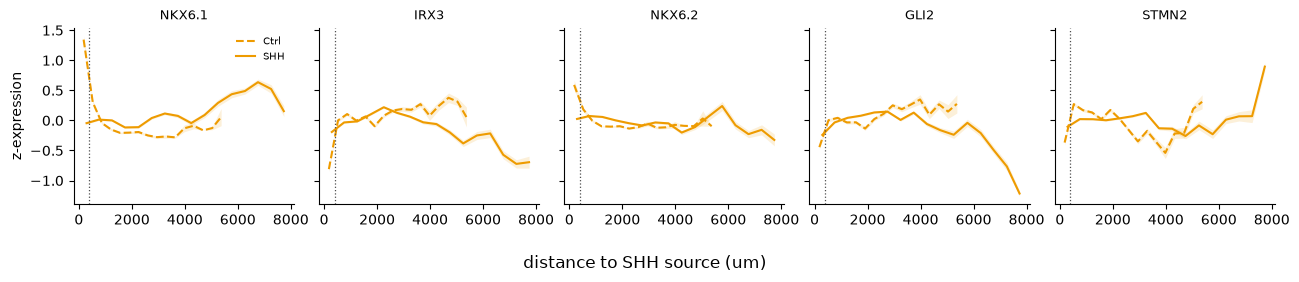

In [35]:
# Per gene, so the pooled curve above is not hiding a single gene carrying it.
fig, axes = plt.subplots(1, len(top_genes), figsize=(2.6 * len(top_genes), 2.8),
                         sharex=True, sharey=True)
for ax, gene in zip(np.atleast_1d(axes), top_genes):
    for c, ls in (("Ctrl", "--"), ("SHH", "-")):
        g = shh_profiles[c].query("gene == @gene").sort_values("center")
        if g.empty:
            continue
        ax.plot(g["center"], g["mean"], ls=ls, lw=1.5,
                color=GROUP_COLORS[str(TOP_SCALE)], label=c)
        ax.fill_between(g["center"], g["mean"] - g["sem"], g["mean"] + g["sem"],
                        color=GROUP_COLORS[str(TOP_SCALE)], alpha=0.15, lw=0)
    ax.axvline(REACH, color="0.3", ls=":", lw=0.9)
    ax.set_title(gene, fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
np.atleast_1d(axes)[0].set_ylabel("z-expression")
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=7)
fig.supxlabel("distance to SHH source (um)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / f"graft_distance_{TOP_SCALE}_dim{TOP_DIM}_per_gene.png",
            dpi=200, bbox_inches="tight")
plt.show()

In [36]:
# The near-source response, as numbers. On this axis the program responds sharply inside the
# first bin and then wanders, so d_half is NOT a decay length here -- `monotonic` says so, and
# the honest statistic is the contrast between the cells nearest the SHH source and the rest.
for c in ("Ctrl", "SHH"):
    st = M.profile_decay_stats(shh_profiles[c], local_reach=REACH)
    st.insert(0, "condition", c)
    print(st[["condition", "gene", "total_change", "monotonic", "d_half"]].round(3).to_string(index=False))

print("\nprogram score near the SHH source vs beyond the local component's reach:")
for c in ("Ctrl", "SHH"):
    prof = shh_profiles[c]
    wide_ = prof.pivot(index="bin", columns="gene", values="mean")[W.index]
    centers = prof.groupby("bin")["center"].first()
    score_ = wide_.to_numpy() @ W.to_numpy()
    near, far = centers.to_numpy() <= REACH, centers.to_numpy() > REACH
    print(f"  {c}: within {REACH:.0f} um {score_[near].mean():+.3f}, "
          f"beyond {score_[far].mean():+.3f}, contrast {score_[near].mean() - score_[far].mean():+.3f}")

condition   gene  total_change  monotonic  d_half
     Ctrl NKX6.1        -1.288      False 393.771
     Ctrl   IRX3         0.867      False 365.117
     Ctrl NKX6.2        -0.686       True 471.068
     Ctrl   GLI2         0.720       True 457.394
     Ctrl  STMN2         0.678      False 363.534
condition   gene  total_change  monotonic   d_half
      SHH NKX6.1         0.200      False 2843.579
      SHH   IRX3        -0.503      False 6584.096
      SHH NKX6.2        -0.349      False 4070.434
      SHH   GLI2        -0.974      False 7188.578
      SHH  STMN2         1.001      False 7444.164

program score near the SHH source vs beyond the local component's reach:
  Ctrl: within 400 um +0.581, beyond -0.099, contrast +0.680
  SHH: within 400 um +0.079, beyond +0.086, contrast -0.007


## Read-out

### A dimension is a combination with signs, not a gene list

An earlier version of this notebook read the 8 genes shared between the local and global sets
as "no room for a distinct program". That was wrong. Three of them enter different dimensions
with **opposite** signs — `IRX3` (`l13 −0.20`, `g11 −0.18`, **`g9 +0.20`**), `MAP2`
(`l9 −0.19`, **`l7 +0.23`**, `g11 −0.19`), `NKX6.1` (`l9 −0.18`, **`l4 +0.16`, `l13 +0.14`,
`g13 +0.13`**) — and the high-minus-low heatmap shows why that matters: `local 13`
(NKX6.1/NKX6.2 up, IRX3/GLI2 down) and `global 9` (IRX3/PAX6/DBX2 up) are near mirror images
of the dorsoventral axis built from overlapping genes. Shared membership is not redundancy.

### Most profiles do not decay, and that changes the answer

**62% of measurable profiles are non-monotonic** — they overshoot their own endpoint and come
back. `d_half` still returns a crossing for those, an arbitrary one. On the 38% that do decay:

| | all measurable | monotonic only |
|---|---|---|
| local `d_half` | 259 µm | **283 µm** |
| global `d_half` | 313 µm | **483 µm** |
| descriptive p | 0.28 | 0.0014 |
| geometry-controlled (`d_half/d_max`) | 0.107 / 0.120, p = 0.59 | **0.118 / 0.214, p = 0.017** |

So *where a program has a coherent gradient at all, the global ones extend ~1.7x further*, and
that survives the geometry control. **Read this as a lead, not a result:** the filter is
post-hoc and shape-dependent, it discards most of the data, and the two scales are filtered at
similar but not identical rates (local 65%, global 60%). The Moran's I AUC (+0.008 between
scales) and the swap control (backwards) still show nothing, so the three measurements
disagree, and the one that separates is the one resting on a chosen subset.

### Does mixing grafted and control organoids hide the signal? (SHH n=11, Ctrl n=6)

**For the local/global question, no — stratifying rules it out more cleanly.** Median Moran's I
AUC is 0.302 vs 0.302 in controls, and in grafted slides *local* is marginally ahead
(0.377 vs 0.356). There was no separation being masked.

**For individual programs, yes, and this is the real finding.** What differs between conditions
is not mainly the length scale but whether a program has a coherent gradient at all:

| | Ctrl non-monotonic | SHH non-monotonic |
|---|---|---|
| `global 9` (dorsal: GLI3/IRX3/PTPRZ1/PAX6/DBX2) | **82%** | **25%** |
| `local 7` | 89% | 57% |
| `local 4` | 77% | 56% |
| all dimensions | ~70% | ~58% |

In controls, four fifths of `global 9`'s profiles have no gradient to measure. With a graft,
three quarters of them do. Its `d_half` rises 319 → 840 µm (p = 0.039) and `local 13`'s
251 → 599 µm (p = 0.004) — but nine dimensions were tested, nothing survives Bonferroni on
6 vs 11 slides, so these are hypotheses for a larger cohort.

### On the independent graft-distance axis, the sharp response is in the CONTROLS

Profiling `local 13`'s genes against `dist_to_SHH` — a physical distance, not derived from the
score — the ventral program is strongly enriched near the source in **controls** (score +0.58
within 400 µm, −0.10 beyond; contrast **+0.68**) and flat in grafted organoids (+0.08 vs +0.09;
contrast −0.01). So grafting does not create a sharper near-source program: it takes a program
that is normally confined to the neighbourhood of the endogenous SHH source and **spreads it
out**, which is the same thing `d_half` says (251 → 599 µm) read on an independent axis.

Caveat on what the axis means: in controls `dist_to_SHH` is distance to the endogenous
SHH-high cells, in grafted slides distance to the graft. Same operational definition, different
biological referent.

### Why the scale separation is hard to show at all

`local 13` — a **local** dimension — has the strongest graft response of the nine. That is not
a contradiction: a field that varies smoothly over millimetres is perfectly readable from a
400 µm neighbourhood, because every neighbourhood sits at a different point on it. A long-range
*pattern* does not require a long-range *mechanism* in the model. Distinguishing the two needs
a program that is discontinuous at the local scale — which is what to look for on CosMx, rather
than more length-scale statistics on this panel.